## Informe CRISP-DM  
## Business Understanding y Data

### **Fase 1: Comprender el negocio**
Primera etapa de CRISP-DM donde se definen los objetivos del proyecto desde la perspectiva del negocio. Se busca el problema en metas técnicas, KPIs y plan de trabajo. En esta fase no se analizan datos sino que se explica el contexto del problema, objetivos, preguntas de negocio y resultado esperado

### Contexto del Negocio
El presente análisis se basa en un dataset de precios y volúmenes de frutas y hortalizas provenientes de la ODEPA, organismo encargado de recopilar información del sector agrícola chileno.

Este dataset contiene información sobre precios y volúmenes de productos comercializados en mercados mayoristas del país, incluyendo variables como producto, variedad, mercado, fecha y precio. Estos datos son recolectados diariamente en los principales mercados de Chile y reflejan el comportamiento real del comercio agrícola

### Objetivo del negocio
Analizar los datos de precios y volúmenes de productos para identificar patrones de consumo y comportamiento del mercado.

### Objetivos del análisis
- Analizar el comportamiento de precios
- Identificar mercados con mayor demanda
- Detectar patrones en los datos


### KPIS
- Precio promedio
- Volumen total por mercado
- Variación de precios

### Características de los datos

 - Variables numéricas: Precio, Volumen, etc.
 - Variables categóricas: Producto, Mercado
 - Variables temporales: Mes, Año

### Limpieza de datos para la siguiente fase

- No se identifican valores nulos en el dataset
- Se detectan valores atípicos que podrían ser tratados
- Se podría aplicar normalización en variables numéricas

## **FASE 2 : COMPRENDER LOS DATOS**
Recolección inicial de datos y análisis exploratorio para familiarizarse con el dataset. Se identifican problemas de calidad, patrones, insights, entre otros.

In [162]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.tree import plot_tree
from sklearn.preprocessing import StandardScaler
import folium
import math
from sklearn.neighbors import KNeighborsRegressor
from sklearn.cluster import KMeans
from sklearn import tree


In [163]:
# Carga del Dataset
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
    name = fn

df = pd.read_excel(name)

Saving categorica.xlsx to categorica (1).xlsx


### Vista general del dataset

In [164]:
#Tamaño del Dataset
df.shape

(49089, 14)

In [165]:
#Muestra los nombres de las columnas del dataset
df.columns

Index(['Variedad', 'Mercado', 'Unidad', 'Dia', 'Precio', 'Fecha', 'Volumen',
       'Producto', 'Latitude', 'Longitude', 'Numero_Unidad', 'Nombre_Unidad',
       'Volumen_Unidad', 'Precio_Unidad'],
      dtype='object')

In [166]:
#muestra las primeras filas del dataset para visualizar su estructura
df.head(5)

,Variedad,Mercado,Unidad,Dia,Precio,Fecha,Volumen,Producto,Latitude,Longitude,Numero_Unidad,Nombre_Unidad,Volumen_Unidad,Precio_Unidad
0,Sin especificar,Terminal La Palmera de La Serena,MALLA 18 KILOS,Lunes,7900.0,2021-01-04,2600.0,Cebolla,-2989028994286880,-7125312099130930,18,KILOS,46800.0,4.388889e+15
1,Sin especificar,Vega Central Mapocho de Santiago,MALLA 18 KILOS,Lunes,7750.0,2021-01-04,520.0,Cebolla,-33427611804927000,-7064949941817030,18,KILOS,9360.0,4.305556e+16
2,Sin especificar,Vega Modelo de Temuco,MALLA 18 KILOS,Lunes,7348.0,2021-01-04,2300.0,Cebolla,-38693614782579200,-7252488766792800,18,KILOS,41400.0,4.082222e+16
3,Sin especificar,Terminal La Palmera de La Serena,MALLA 18 KILOS,Martes,7750.0,2021-01-05,2000.0,Cebolla,-2989028994286880,-7125312099130930,18,KILOS,36000.0,4.305556e+16
4,Sin especificar,Vega Modelo de Temuco,MALLA 18 KILOS,Martes,8000.0,2021-01-05,1500.0,Cebolla,-38693614782579200,-7252488766792800,18,KILOS,27000.0,4.444444e+16


In [167]:
# Revisión de los tipos de datos
df.dtypes

,0
Variedad,object
Mercado,object
Unidad,object
Dia,object
Precio,float64
Fecha,datetime64[ns]
Volumen,float64
Producto,object
Latitude,int64
Longitude,int64


In [168]:
# Revisión de los tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49089 entries, 0 to 49088
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Variedad        49089 non-null  object        
 1   Mercado         49089 non-null  object        
 2   Unidad          49089 non-null  object        
 3   Dia             49089 non-null  object        
 4   Precio          49089 non-null  float64       
 5   Fecha           49089 non-null  datetime64[ns]
 6   Volumen         49089 non-null  float64       
 7   Producto        49089 non-null  object        
 8   Latitude        49089 non-null  int64         
 9   Longitude       49089 non-null  int64         
 10  Numero_Unidad   49089 non-null  int64         
 11  Nombre_Unidad   49089 non-null  object        
 12  Volumen_Unidad  49089 non-null  float64       
 13  Precio_Unidad   49089 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(3), object(6)


### Valores nulos y calidad

In [169]:
# Valores nulos por columna
for feature in df.columns:
    print('Total de valores nulos de', feature, '=', df[feature].isna().sum())

Total de valores nulos de Variedad = 0
Total de valores nulos de Mercado = 0
Total de valores nulos de Unidad = 0
Total de valores nulos de Dia = 0
Total de valores nulos de Precio = 0
Total de valores nulos de Fecha = 0
Total de valores nulos de Volumen = 0
Total de valores nulos de Producto = 0
Total de valores nulos de Latitude = 0
Total de valores nulos de Longitude = 0
Total de valores nulos de Numero_Unidad = 0
Total de valores nulos de Nombre_Unidad = 0
Total de valores nulos de Volumen_Unidad = 0
Total de valores nulos de Precio_Unidad = 0


In [170]:
#Cuenta cuántos datos vacíos o nulos hay en cada columna del Dataset
#No se identifican valores nulos en el dataset, lo que facilita el análisis y evita la necesidad de imputación de datos.
df.isna().sum()

,0
Variedad,0
Mercado,0
Unidad,0
Dia,0
Precio,0
Fecha,0
Volumen,0
Producto,0
Latitude,0
Longitude,0


In [171]:
#Cantidad de datos sin especificar
(df["Variedad"] == "Sin especificar").sum()

np.int64(9975)

### Estadística

In [172]:
#Resumen estadístico de las columnas numéricas del DataFrame
resultado = df.describe()

resultado = resultado.applymap(lambda x: f"{x:,.0f}".replace(",", "."))

resultado

/tmp/ipykernel_48774/1333203938.py:4: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  resultado = resultado.applymap(lambda x: f"{x:,.0f}".replace(",", "."))


,Precio,Fecha,Volumen,Latitude,Longitude,Numero_Unidad,Volumen_Unidad,Precio_Unidad
count,49.089,49.089,49.089,49.089,49.089,49.089,49.089,49.089
mean,35.200,..0f,619,-20.347.343.320.541.616,-6.343.303.949.515.051,70,12.349,4.676.789.347.684.028
min,400,..0f,1,-38.693.614.782.579.200,-7.307.157.073.479.410,8,60,30
25%,5.769,..0f,100,-33.482.984.251.005.600,-7.209.974.646.092.060,15,2.880,428
50%,8.250,..0f,300,-32.785.622.816.862.600,-7.125.312.099.130.930,18,6.400,938
75%,13.646,..0f,700,-3.657.060.167.406.140,-7.064.949.941.817.030,20,12.500,5.416.666.666.666.660
max,650.000,..0f,16.800,-334.330.979.830.953,-711.884.954.316.865,450,336.000,51.194.444.444.444.400
std,72.732,nan,912,15.346.973.924.779.770,2.137.825.060.147.164,135,18.025,9.669.527.994.743.048


In [173]:
# Considerando solo las columnas de tipo object
df.describe(include="object")

,Variedad,Mercado,Unidad,Dia,Producto,Nombre_Unidad
count,49089,49089,49089,49089,49089,49089
unique,76,12,32,5,11,2
top,Sin especificar,Mercado Mayorista Lo Valledor de Santiago,BANDEJA 18 KILOS,Jueves,Lechuga,KILOS
freq,9975,10045,6995,10639,9633,39104


### Valores únicos y conteos

In [174]:
#Valores unicos
df["Producto"].unique()

array(['Cebolla', 'Lechuga', 'LimÃ³n', 'Manzana', 'Naranja', 'Palta',
       'Papa', 'Pera', 'Tomate', 'Zanahoria', 'Uva'], dtype=object)

In [175]:
df["Variedad"].value_counts()

,count
Variedad,
Sin especificar,9975
Larga vida,5635
Escarola,3783
Conconina,3076
Granny Smith,2484
...,...
Florentina,2
CalmerÃ­a,2
Atwood Navel,1


In [176]:
df["Mercado"].value_counts()

,count
Mercado,
Mercado Mayorista Lo Valledor de Santiago,10045
Terminal La Palmera de La Serena,6440
Femacal de La Calera,6175
Vega Central Mapocho de Santiago,5412
Vega Modelo de Temuco,4976
Macroferia Regional de Talca,3802
Feria Lagunitas de Puerto Montt,3529
Terminal HortofrutÃ­cola Agro ChillÃ¡n,3423
Vega Monumental ConcepciÃ³n,2934


### Medidas del precio

In [177]:
#Calcula la media de los precios
df["Precio"].mean()

np.float64(35200.01823219051)

In [178]:
#calcula la mediana de los precios
df["Precio"].median()

8250.0

In [179]:
#calcula la desviación estándar de los precios

df["Precio"].std()

72732.30018722518

### Transformación de fechas y análisis mensual

In [180]:
#Convierte la fecha y calcula el precio promedio por mes
df["Fecha"] = pd.to_datetime(df["Fecha"])

df["Mes"] = df["Fecha"].dt.month
df["Año"] = df["Fecha"].dt.year

df.groupby("Mes")["Precio"].mean()

,Precio
Mes,
1,34288.293822
2,34085.806434
3,35084.553886
4,34764.085901
5,31918.032522
6,31452.911374
7,32742.822424
8,35958.692924
9,37391.410495


### Precio por mercado y volumen por mercado

In [181]:
#Volumen del Mercado 2kpi y 5to
resultado = df.groupby("Mercado")["Volumen"].sum().sort_values(ascending=False)
resultado.apply(lambda x: f"{int(x):,}".replace(",", "."))

,Volumen
Mercado,
Mercado Mayorista Lo Valledor de Santiago,11.654.244
Terminal La Palmera de La Serena,4.526.662
Macroferia Regional de Talca,3.552.931
Vega Modelo de Temuco,3.176.805
Vega Central Mapocho de Santiago,1.431.503
Vega Monumental ConcepciÃ³n,1.299.585
Femacal de La Calera,1.243.563
Feria Lagunitas de Puerto Montt,1.164.168
Comercializadora del Agro de LimarÃ­,861.312


In [182]:
#Precio del Mercado 1kpi
resultado = df.groupby("Mercado")["Precio"].mean()
resultado.apply(lambda x: f"${int(x):,}".replace(",", "."))

,Precio
Mercado,
AgrÃ­cola del Norte S.A. de Arica,$6.625
Comercializadora del Agro de LimarÃ­,$51.494
Femacal de La Calera,$9.383
Feria Lagunitas de Puerto Montt,$12.806
Macroferia Regional de Talca,$9.320
Mapocho Venta Directa de Santiago,$12.503
Mercado Mayorista Lo Valledor de Santiago,$62.187
Terminal HortofrutÃ­cola Agro ChillÃ¡n,$7.954
Terminal La Palmera de La Serena,$77.991


### Outliers del precio

In [183]:
#Detecta valores atípicos (outliers) en los precios usando el rango intercuartílico
Q1 = df["Precio"].quantile(0.25)
Q3 = df["Precio"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df[(df["Precio"] < limite_inferior) | (df["Precio"] > limite_superior)]

len(outliers)

7017

### Visualización de distribución y outliers

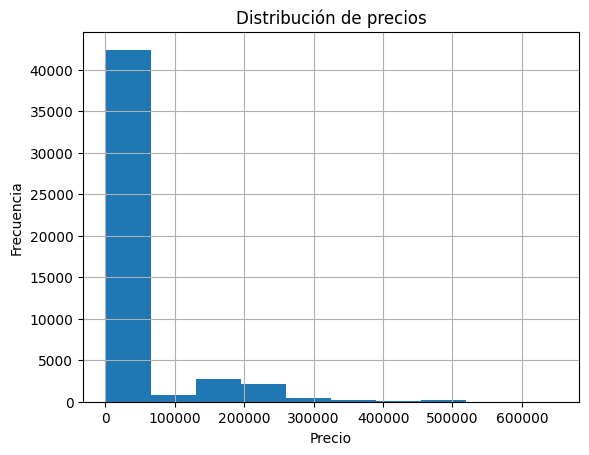

In [184]:
#Muestra la distribución de los precios para analizar su frecuencia y comportamiento 4 kpi

df["Precio"].hist()
plt.title("Distribución de precios")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.show()

Se observa que el precio presenta una alta dispersión, evidenciada en la diferencia entre el valor mínimo y máximo. Además, la media es considerablemente mayor que la mediana, lo que indica la presencia de valores extremos (outliers)

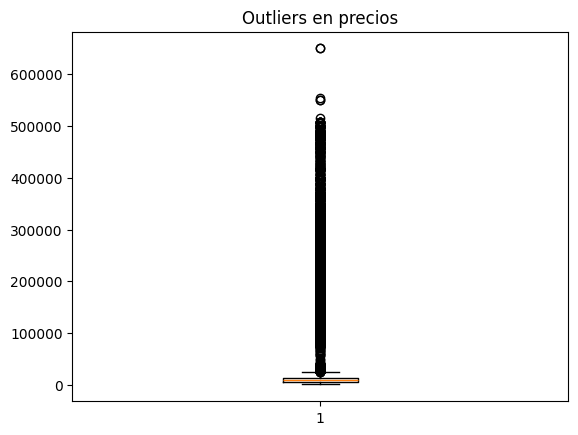

In [185]:
#Muestra un boxplot para visualizar la distribución de precios y detectar outliers
plt.boxplot(df["Precio"])
plt.title("Outliers en precios")
plt.show()

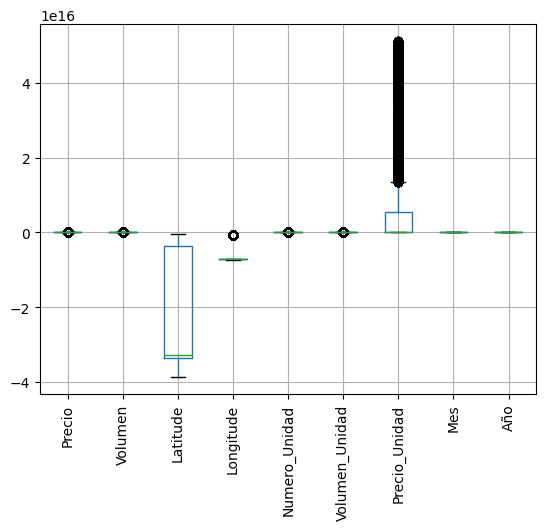

In [186]:
#muestra un boxplot de todas las variables numéricas para detectar outliers y su distribución
df.boxplot()
plt.xticks(rotation=90)
plt.show()

### Variabilidad por producto

In [187]:
#Mide la variabilidad del precio por producto; valores altos indican mayor cambio y bajos mayor estabilidad 3kpi
df.groupby("Producto")["Precio"].std().sort_values(ascending=False)

,Precio
Producto,
Naranja,125999.306293
Manzana,106231.293605
Pera,101073.113582
Palta,7302.581912
LimÃ³n,6027.255232
Tomate,5429.915758
Uva,3958.783553
Cebolla,3503.060363
Zanahoria,3452.297915


### Tratamiento "Sin Especificar"

In [188]:
for col in df.columns:
    cantidad = (df[col].astype(str).str.strip().str.lower() == "sin especificar").sum()
    if cantidad > 0:
        print(f"{col}: {cantidad}")

Variedad: 9975


**Antes de decidir qué hacer, necesitamos saber qué porcentaje representan.**

In [189]:
print(f"Porcentaje: {(df['Variedad'] == 'Sin especificar').mean()*100:.2f}%")

Porcentaje: 20.32%


Buscar que productos tienen "Sin especificar"

In [190]:
df[df["Variedad"] == "Sin especificar"]["Producto"].unique()

array(['Cebolla', 'LimÃ³n', 'Zanahoria'], dtype=object)

Imputar

In [191]:
moda_variedad = (
    df[df["Variedad"] != "Sin especificar"]
    .groupby("Producto")["Variedad"]
    .agg(lambda x: x.mode().iloc[0])
)

# Imputar donde exista una moda
for producto, variedad in moda_variedad.items():
    df.loc[
        (df["Producto"] == producto) &
        (df["Variedad"] == "Sin especificar"),
        "Variedad"
    ] = variedad

In [192]:
print(f"Total de 'Sin especificar': {(df['Variedad'] == 'Sin especificar').sum()}")

Total de 'Sin especificar': 6947


Se identificaron 9.975 registros (20,32%) con el valor "Sin especificar" en la variable Variedad. Para su tratamiento, se aplicó una imputación utilizando la moda por producto, reemplazando los valores únicamente en aquellos productos que contaban con al menos una variedad registrada distinta de "Sin especificar". Este procedimiento permitió imputar 3.028 registros, reduciendo la cantidad de valores "Sin especificar" a 6.947. Los registros restantes correspondieron a productos que no disponían de información suficiente para realizar una imputación confiable, por lo que se conservaron para evitar introducir información artificial en el conjunto de datos.

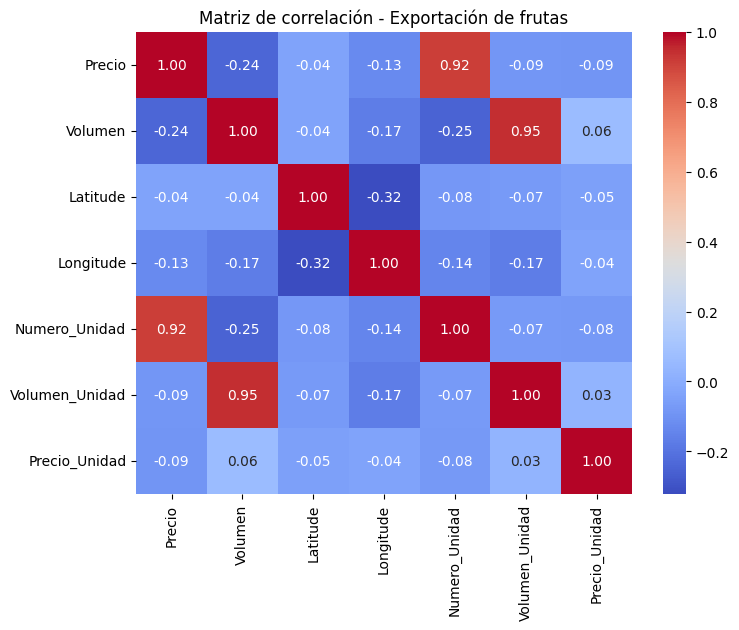

In [193]:
# Seleccionar solo columnas numéricas
df_numerico = df.select_dtypes(include=['int64', 'float64'])

# Calcular correlación
corr = df_numerico.corr()

# Crear mapa de calor
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de correlación - Exportación de frutas")
plt.show()

# **Fase 3 — Data Preparation**

En esta etapa se realizan las transformaciones necesarias para preparar los datos antes del entrenamiento de los modelos predictivos.

Se aplican técnicas de tratamiento de outliers, selección de variables, división de datos y escalado, con el objetivo de mejorar el rendimiento y la capacidad de generalización de los modelos

## Tratamiento de Outliers
Los valores atípicos pueden afectar negativamente el rendimiento de los modelos predictivos, generando errores y reduciendo la capacidad de generalización.

Para reducir este impacto, se aplica tratamiento de outliers utilizando el método del rango intercuartílico (IQR)

### **Distribución de Outliers por Producto**

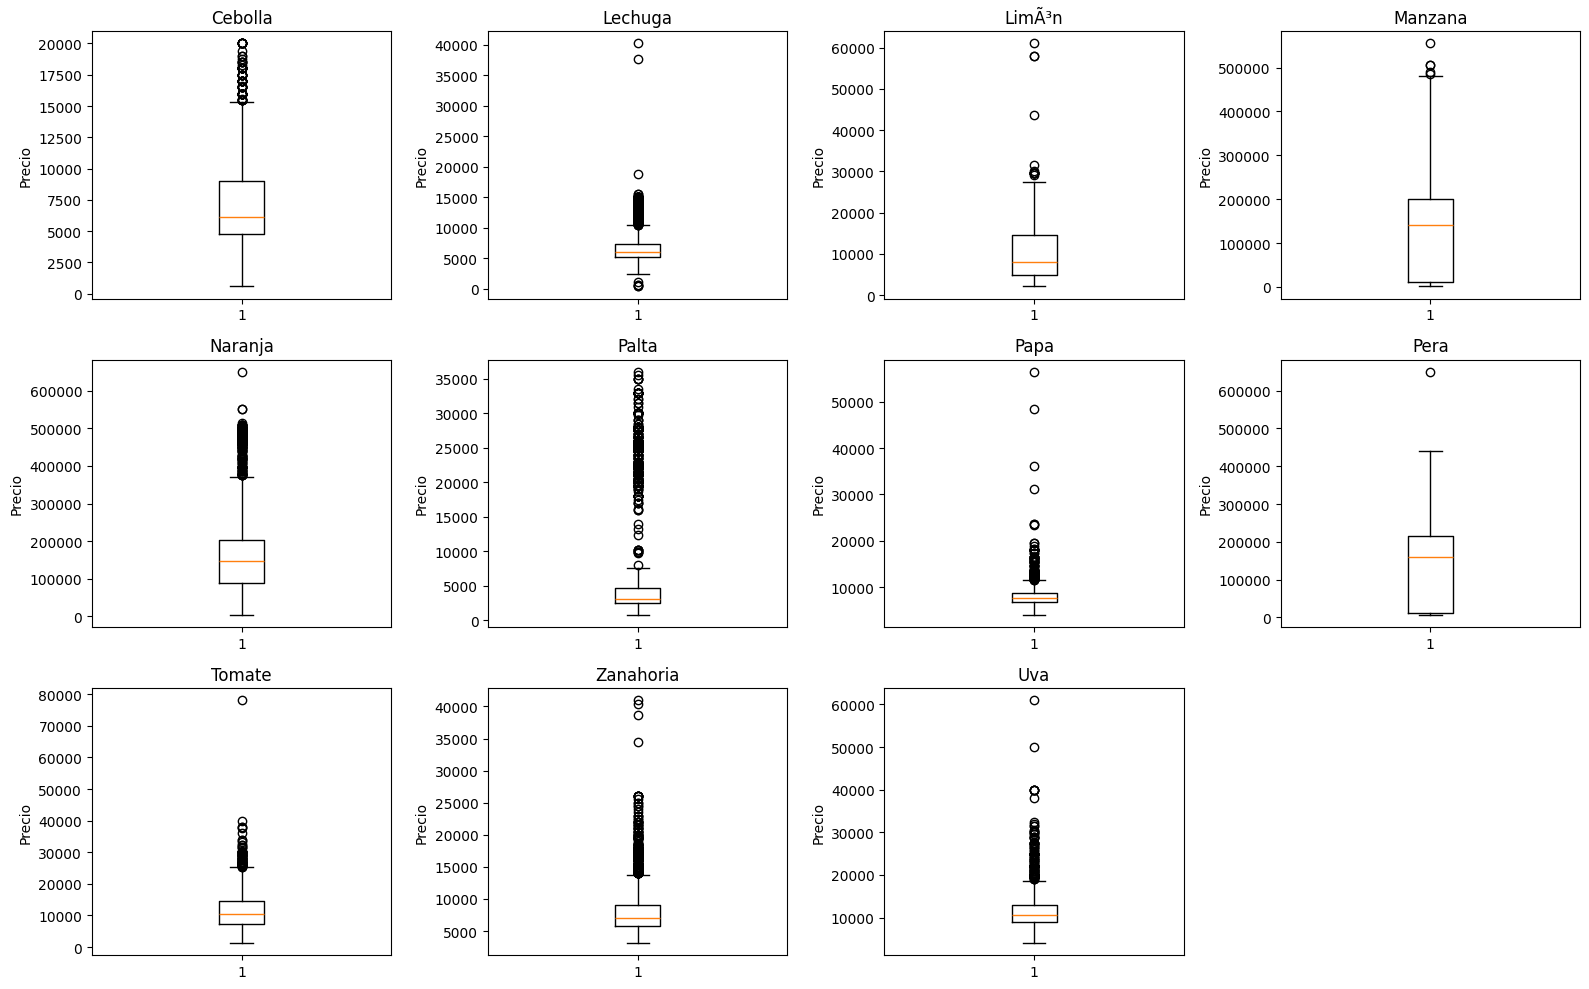

In [194]:
df_original = df.copy()

df_original["Precio"] = pd.to_numeric(
    df_original["Precio"],
    errors="coerce"
)

df_original = df_original.dropna(
    subset=["Precio", "Producto"]
)

productos = df_original["Producto"].unique()

n = len(productos)

cols = 4

rows = (n // cols) + (n % cols > 0)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16,10)
)

axes = axes.flatten()

for i, producto in enumerate(productos):

    data = df_original[
        df_original["Producto"] == producto
    ]["Precio"]

    axes[i].boxplot(data)

    axes[i].set_title(producto)

    axes[i].set_ylabel("Precio")

for j in range(i + 1, len(axes)):

    fig.delaxes(axes[j])

plt.tight_layout()

plt.show()

### Se generan gráficos Boxplot para cada producto con el fin de visualizar la distribución de los precios identificar posibles valores atípicos (outliers)

### **Cantidad de Outliers Antes del Tratamiento**

In [195]:
# Cantidad total de outliers por producto (IQR)

total_outliers = 0

for producto in df["Producto"].unique():

    data = df[df["Producto"] == producto]["Precio"]

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    total_outliers += ((data < lim_inf) | (data > lim_sup)).sum()

print(f"Cantidad total de outliers: {total_outliers}")

Cantidad total de outliers: 2060


### Se calcula la cantidad de valores atípicos (outliers) presentes en la columna de precios utilizando el método IQR, lo cual no dió la cantidad de 2060 outliers

In [196]:
print(df.columns.tolist())

['Variedad', 'Mercado', 'Unidad', 'Dia', 'Precio', 'Fecha', 'Volumen', 'Producto', 'Latitude', 'Longitude', 'Numero_Unidad', 'Nombre_Unidad', 'Volumen_Unidad', 'Precio_Unidad', 'Mes', 'Año']


### **Aplicación del Método IQR**

In [197]:
media_producto = df.groupby(
    "Producto"
)["Precio"].transform("mean")

df["Precio_tratado"] = np.where(

    ((df["Precio"] < lim_inf) |

    (df["Precio"] > lim_sup)),

    media_producto,

    df["Precio"]

)

### Se aplica el método IQR para tratar los valores atípicos, reemplazando los precios fuera del rango permitido por el promedio correspondiente de cada producto

### **Cantidad de Outliers Después del Tratamiento**

In [198]:
total = 0

for producto in df["Producto"].unique():

    data = df[df["Producto"] == producto]["Precio_tratado"]

    Q1 = data.quantile(.25)
    Q3 = data.quantile(.75)
    IQR = Q3 - Q1

    li = Q1 - 1.5 * IQR
    ls = Q3 + 1.5 * IQR

    total += ((data < li) | (data > ls)).sum()

print(total)

1755


----------------------------------------------------------------------------------------------------

In [199]:
for producto in df["Producto"].unique():

    mask = df["Producto"] == producto

    data = df.loc[mask, "Precio_tratado"]

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    li = Q1 - 1.5 * IQR
    ls = Q3 + 1.5 * IQR

    media = data.mean()

    df.loc[
        mask & ((df["Precio_tratado"] < li) | (df["Precio_tratado"] > ls)),
        "Precio_tratado"
    ] = media

In [200]:
total = 0

for producto in df["Producto"].unique():

    data = df[df["Producto"] == producto]["Precio_tratado"]

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    li = Q1 - 1.5 * IQR
    ls = Q3 + 1.5 * IQR

    total += ((data < li) | (data > ls)).sum()

print(total)

1416


Antes del tratamiento específico por producto se identificaron 1.755 valores atípicos. Tras aplicar nuevamente el método IQR utilizando la media de cada producto para reemplazar los valores extremos y volver a evaluar el conjunto de datos, la cantidad de outliers se redujo a 1.416 registros, lo que representa una disminución aproximada del 19,3 % respecto al estado inicial posterior al primer tratamiento.


---------------------------------------------------------------------------------------------------------------------------------------

### **Visualización de Columnas del Dataset**

In [201]:
df["Precio_Unidad"] = df["Precio_tratado"] / df["Numero_Unidad"]

In [202]:
df.columns

Index(['Variedad', 'Mercado', 'Unidad', 'Dia', 'Precio', 'Fecha', 'Volumen',
       'Producto', 'Latitude', 'Longitude', 'Numero_Unidad', 'Nombre_Unidad',
       'Volumen_Unidad', 'Precio_Unidad', 'Mes', 'Año', 'Precio_tratado'],
      dtype='object')

Se utilizó df.columns para visualizar los nombres de las columnas presentes en el dataset, permitiendo verificar las variables disponibles antes de seleccionar los atributos para los modelos.

### **Definición de Variables para los Modelos**

In [203]:
variables = [
    ["Precio_Unidad", "Longitude"],
    ["Volumen"],
    ["Precio_Unidad", "Volumen"],
    ["Precio_tratado", "Volumen"]
]

Aquí se definieron distintas combinaciones de variables para probar los modelos. Cada lista representa un conjunto de variables de entrada utilizadas para predecir Volumen_Unidad

In [204]:
df_numerico.columns

Index(['Precio', 'Volumen', 'Latitude', 'Longitude', 'Numero_Unidad',
       'Volumen_Unidad', 'Precio_Unidad'],
      dtype='object')

### **REGRESIÓN LINEAL**

### **Ejecuciones del Modelo**

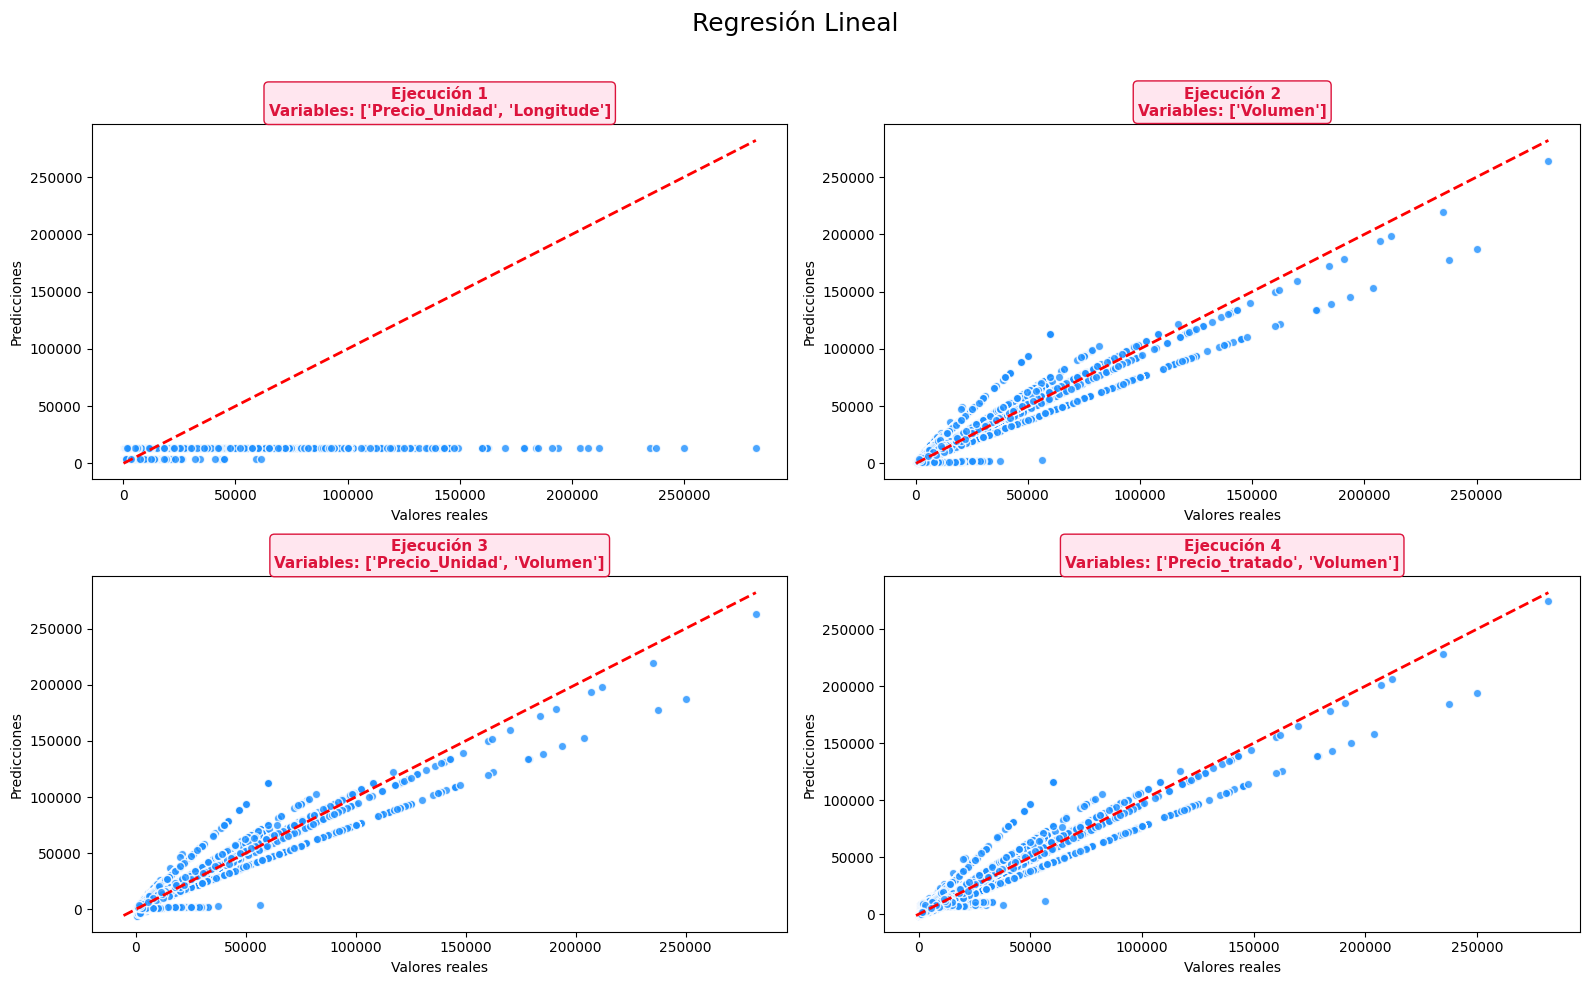

In [205]:
fig, axes = plt.subplots(2, 2, figsize=(16,10))
fig.suptitle("Regresión Lineal", fontsize=18)

for i, variable in enumerate(variables):

    X = df[variable]
    y = df["Volumen_Unidad"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.33,
        random_state=42
    )

    modelo = LinearRegression()
    modelo.fit(X_train, y_train)

    pred = modelo.predict(X_test)

    ax = axes[i//2, i%2]

    ax.scatter(y_test, pred,
               color="dodgerblue",
               edgecolors="white",
               alpha=0.8)

    minimo = min(y_test.min(), pred.min())
    maximo = max(y_test.max(), pred.max())

    ax.plot(
        [minimo, maximo],
        [minimo, maximo],
        'r--',
        linewidth=2
    )

    ax.set_title(
        f"Ejecución {i+1}\nVariables: {variable}",
        fontsize=11,
        color="crimson",
        fontweight="bold",
        bbox=dict(facecolor="#ffe6ef",
                  edgecolor="crimson",
                  boxstyle="round")
    )

    ax.set_xlabel("Valores reales")
    ax.set_ylabel("Predicciones")

plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

Análisis de las ejecuciones:
Los gráficos muestran la relación entre los valores reales y los valores predichos para las cuatro ejecuciones del modelo de Regresión Lineal. Se observa una alta dispersión respecto de la línea de referencia, indicando que el modelo presenta dificultades para ajustarse a la variabilidad de la variable objetivo. Esto sugiere que la relación entre las variables predictoras y Volumen_Unidad no puede representarse adecuadamente mediante un modelo lineal, generando predicciones con un error considerable.

### Evaluación del Modelo

In [206]:
resultados = []

for variable in variables:

    X = df[variable]
    y = df["Volumen_Unidad"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = LinearRegression()

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    r2_train = r2_score(y_train, pred_train)
    rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))

    r2_test = r2_score(y_test, pred_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))

    print(f"Variables: {variable}")
    print(f"R² Train: {r2_train:.4f}")
    print(f"RMSE Train: {rmse_train:.2f}")
    print(f"R² Test: {r2_test:.4f}")
    print(f"RMSE Test: {rmse_test:.2f}")
    print("-"*40)

    resultados.append({
        "Variables": str(variable),
        "R² Train": round(r2_train, 4),
        "RMSE Train": round(rmse_train, 2),
        "R² Test": round(r2_test, 4),
        "RMSE Test": round(rmse_test, 2)
    })

evaluacion = pd.DataFrame(resultados)

mejor_lineal = evaluacion.loc[
    evaluacion["R² Test"].idxmax()
]

evaluacion

Variables: ['Precio_Unidad', 'Longitude']
R² Train: 0.0293
RMSE Train: 17603.14
R² Test: 0.0290
RMSE Test: 18070.58
----------------------------------------
Variables: ['Volumen']
R² Train: 0.8973
RMSE Train: 5724.94
R² Test: 0.8974
RMSE Test: 5872.87
----------------------------------------
Variables: ['Precio_Unidad', 'Volumen']
R² Train: 0.8985
RMSE Train: 5692.23
R² Test: 0.8986
RMSE Test: 5838.87
----------------------------------------
Variables: ['Precio_tratado', 'Volumen']
R² Train: 0.9243
RMSE Train: 4916.74
R² Test: 0.9233
RMSE Test: 5078.94
----------------------------------------


,Variables,R² Train,RMSE Train,R² Test,RMSE Test
0,"['Precio_Unidad', 'Longitude']",0.0293,17603.14,0.0290,18070.58
1,['Volumen'],0.8973,5724.94,0.8974,5872.87
2,"['Precio_Unidad', 'Volumen']",0.8985,5692.23,0.8986,5838.87
3,"['Precio_tratado', 'Volumen']",0.9243,4916.74,0.9233,5078.94


In [207]:
resultados = []

for variable in variables:

    X = df[variable]
    y = df["Volumen_Unidad"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = LinearRegression()

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    resultados.append({

        "Variables": str(variable),

        "R² Train": round(r2_score(y_train, pred_train),4),
        "RMSE Train": round(np.sqrt(mean_squared_error(y_train,pred_train)),2),

        "R² Test": round(r2_score(y_test,pred_test),4),
        "RMSE Test": round(np.sqrt(mean_squared_error(y_test,pred_test)),2)

    })

comparacion = pd.DataFrame(resultados)

comparacion

,Variables,R² Train,RMSE Train,R² Test,RMSE Test
0,"['Precio_Unidad', 'Longitude']",0.0293,17603.14,0.0290,18070.58
1,['Volumen'],0.8973,5724.94,0.8974,5872.87
2,"['Precio_Unidad', 'Volumen']",0.8985,5692.23,0.8986,5838.87
3,"['Precio_tratado', 'Volumen']",0.9243,4916.74,0.9233,5078.94


La comparación de las cuatro ejecuciones evidencia que la selección de variables influye directamente en el desempeño de la Regresión Lineal. La primera ejecución presentó un rendimiento limitado debido a la baja capacidad explicativa de las variables utilizadas. Al incorporar la variable Volumen en la segunda ejecución, el modelo mejoró significativamente su capacidad predictiva. La tercera ejecución obtuvo un desempeño ligeramente superior al combinar Volumen con Precio_Unidad. Finalmente, la cuarta ejecución alcanzó el mejor rendimiento al utilizar Precio_tratado junto con Volumen, obteniendo el mayor coeficiente de determinación en el conjunto de prueba (R² = 0.9233) y el menor error de predicción (RMSE = 5078.94). Estos resultados indican que esta combinación de variables es la más adecuada para estimar la variable objetivo mediante Regresión Lineal.

In [208]:
print(variables)

[['Precio_Unidad', 'Longitude'], ['Volumen'], ['Precio_Unidad', 'Volumen'], ['Precio_tratado', 'Volumen']]


### **ÁRBOL DE DECISIÓN**



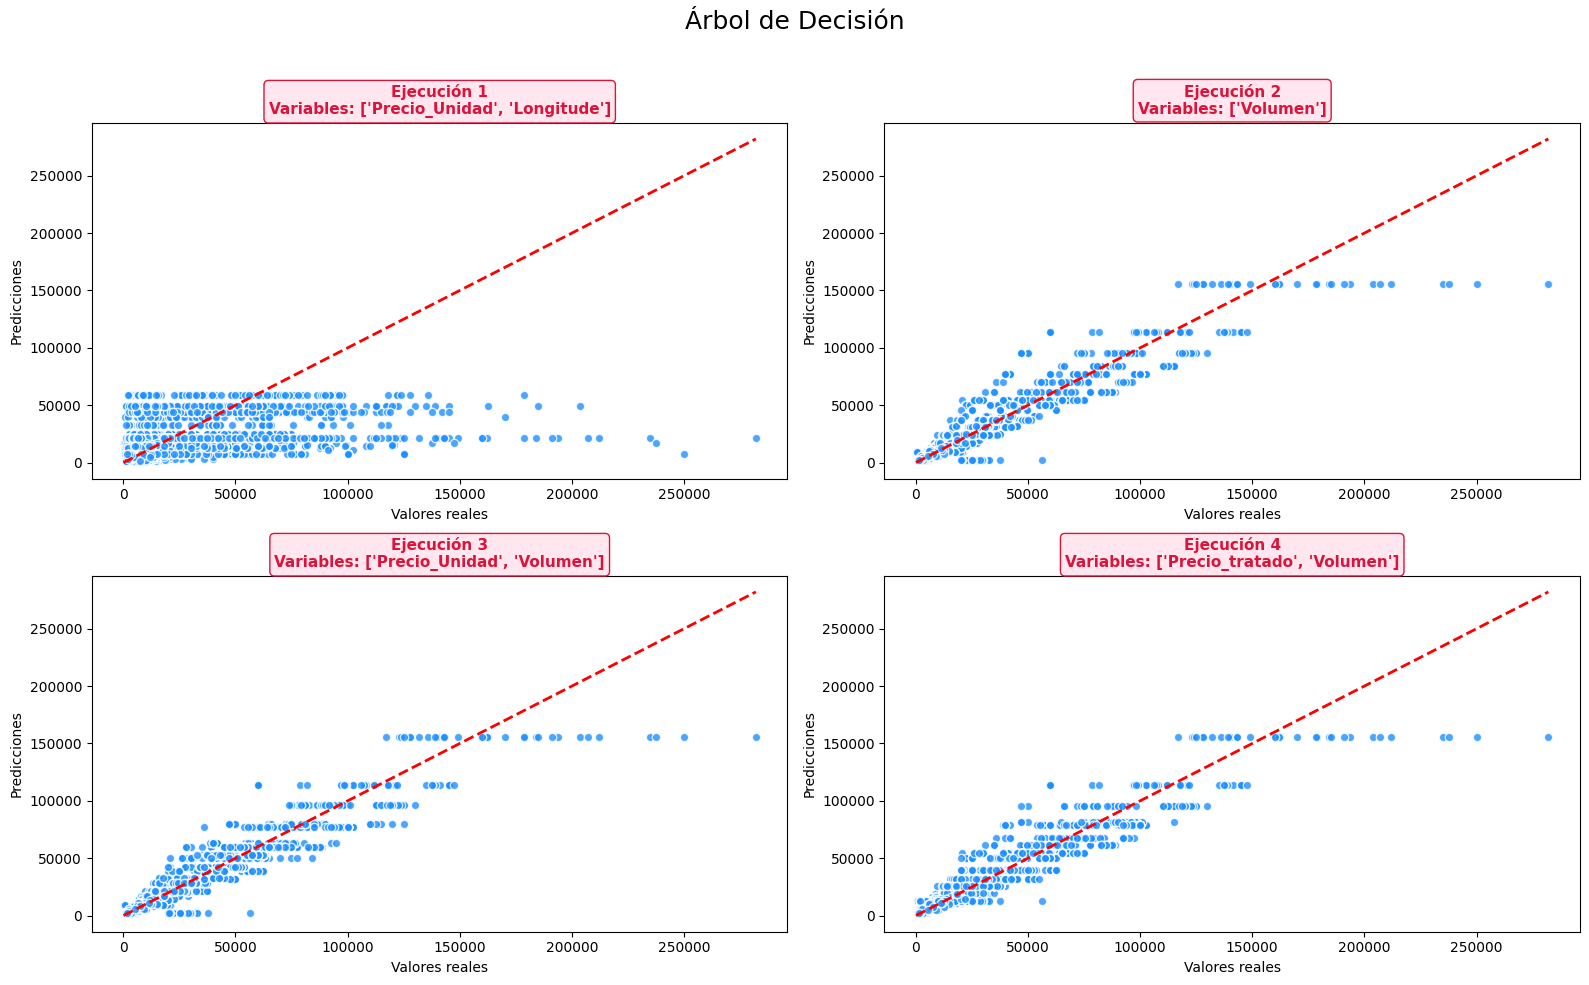

In [209]:
fig, axes = plt.subplots(2, 2, figsize=(16,10))
fig.suptitle("Árbol de Decisión", fontsize=18)

for i, variable in enumerate(variables):

    X = df[variable]
    y = df["Volumen_Unidad"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=50,
    random_state=42
)

    modelo.fit(X_train, y_train)

    pred = modelo.predict(X_test)

    ax = axes[i//2, i%2]

    ax.scatter(
        y_test,
        pred,
        color="dodgerblue",
        edgecolors="white",
        alpha=0.8
    )

    minimo = min(y_test.min(), pred.min())
    maximo = max(y_test.max(), pred.max())

    ax.plot(
        [minimo, maximo],
        [minimo, maximo],
        "r--",
        linewidth=2
    )

    ax.set_title(
        f"Ejecución {i+1}\nVariables: {variable}",
        fontsize=11,
        color="crimson",
        fontweight="bold",
        bbox=dict(facecolor="#ffe6ef",
                  edgecolor="crimson",
                  boxstyle="round")
    )

    ax.set_xlabel("Valores reales")
    ax.set_ylabel("Predicciones")

plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

### **Evaluación del Modelo**

In [210]:
resultados = []

for variable in variables:

    X = df[variable]
    y = df["Volumen_Unidad"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = DecisionTreeRegressor(
        max_depth=5,
        min_samples_split=20,
        min_samples_leaf=50,
        random_state=42
    )

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    resultados.append({

        "Variables": str(variable),

        "R² Train": round(r2_score(y_train, pred_train), 4),
        "RMSE Train": round(np.sqrt(mean_squared_error(y_train, pred_train)), 2),

        "R² Test": round(r2_score(y_test, pred_test), 4),
        "RMSE Test": round(np.sqrt(mean_squared_error(y_test, pred_test)), 2)

    })

evaluacion = pd.DataFrame(resultados)

mejor_arbol = evaluacion.loc[
    evaluacion["R² Test"].idxmax()
]

evaluacion

,Variables,R² Train,RMSE Train,R² Test,RMSE Test
0,"['Precio_Unidad', 'Longitude']",0.3167,14768.81,0.3168,15157.41
1,['Volumen'],0.9194,5073.93,0.9170,5284.43
2,"['Precio_Unidad', 'Volumen']",0.9272,4819.60,0.9286,4899.09
3,"['Precio_tratado', 'Volumen']",0.9294,4748.85,0.9283,4910.10


### **Comparación del Modelo**

In [211]:
resultados = []

for variable in variables:

    X = df[variable]
    y = df["Volumen_Unidad"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=50,
    random_state=42
)
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    r2_train = r2_score(y_train, pred_train)
    r2_test = r2_score(y_test, pred_test)

    rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))
    rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))

    resultados.append({

        "Variables": str(variable),

        "R² Train": round(r2_train,4),
        "R² Test": round(r2_test,4),
        "Dif R²": round(abs(r2_train-r2_test),4),

        "RMSE Train": round(rmse_train,2),
        "RMSE Test": round(rmse_test,2),
        "Dif RMSE": round(abs(rmse_train-rmse_test),2)

    })

comparacion = pd.DataFrame(resultados)

comparacion

,Variables,R² Train,R² Test,Dif R²,RMSE Train,RMSE Test,Dif RMSE
0,"['Precio_Unidad', 'Longitude']",0.3167,0.3168,0.0001,14768.81,15157.41,388.60
1,['Volumen'],0.9194,0.9170,0.0024,5073.93,5284.43,210.50
2,"['Precio_Unidad', 'Volumen']",0.9272,0.9286,0.0014,4819.60,4899.09,79.49
3,"['Precio_tratado', 'Volumen']",0.9294,0.9283,0.0010,4748.85,4910.10,161.25


El Árbol de Decisión Regressor presentó un buen desempeño en la predicción del volumen de ventas. La mejor configuración fue la Ejecución 3, utilizando las variables Precio_Unidad y Volumen, ya que obtuvo el mayor coeficiente de determinación en el conjunto de prueba (R² = 0.9286) y el menor error de predicción (RMSE = 4899.09). Además, las diferencias entre las métricas de entrenamiento y prueba fueron muy pequeñas en las cuatro ejecuciones, lo que indica que el modelo presenta una buena capacidad de generalización y proporciona predicciones confiables sobre datos no utilizados durante el entrenamiento.

### **RANDOM FOREST**

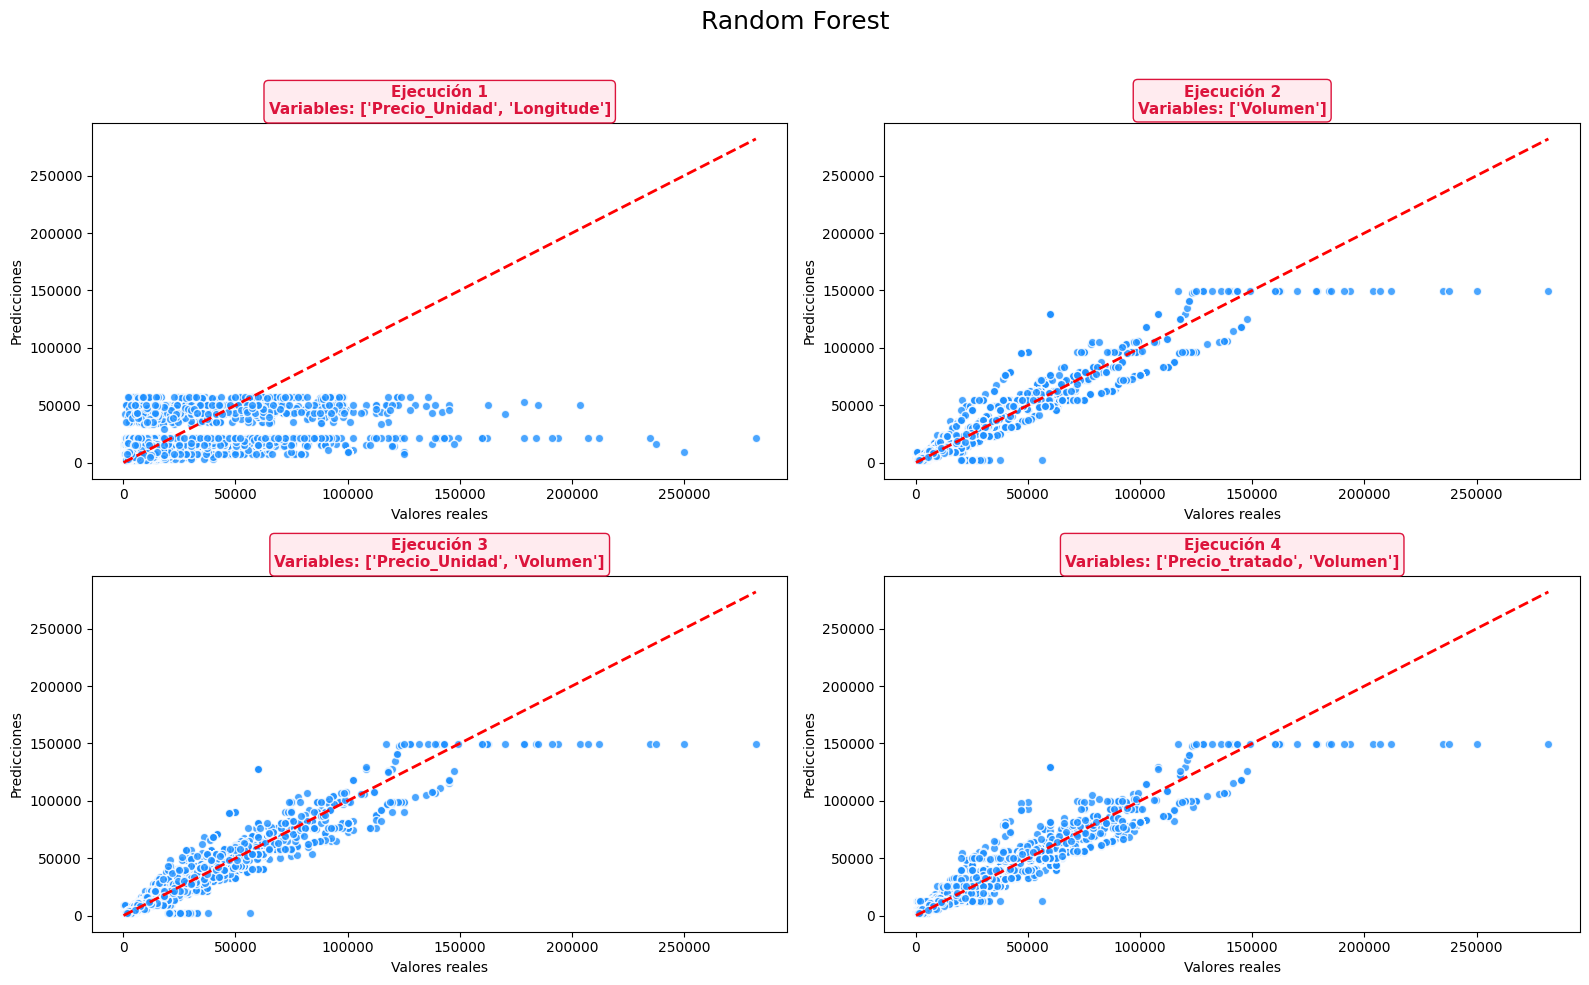

In [212]:
fig, axes = plt.subplots(2, 2, figsize=(16,10))
fig.suptitle("Random Forest", fontsize=18)

for i, variable in enumerate(variables):

    X = df[variable]
    y = df["Volumen_Unidad"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        min_samples_split=20,
        min_samples_leaf=50,
        random_state=42,
        n_jobs=-1
    )

    modelo.fit(X_train, y_train)

    pred = modelo.predict(X_test)

    ax = axes[i//2, i%2]

    ax.scatter(
        y_test,
        pred,
        color="dodgerblue",
        edgecolors="white",
        alpha=0.8
    )

    minimo = min(y_test.min(), pred.min())
    maximo = max(y_test.max(), pred.max())

    ax.plot(
        [minimo, maximo],
        [minimo, maximo],
        "r--",
        linewidth=2
    )

    ax.set_title(
        f"Ejecución {i+1}\nVariables: {variable}",
        fontsize=11,
        color="crimson",
        fontweight="bold",
        bbox=dict(
            facecolor="#ffebef",
            edgecolor="crimson",
            boxstyle="round"
        )
    )

    ax.set_xlabel("Valores reales")
    ax.set_ylabel("Predicciones")

plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

### **Evaluación del modelo**

In [213]:
resultados = []

for variable in variables:

    X = df[variable]
    y = df["Volumen_Unidad"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        min_samples_split=20,
        min_samples_leaf=50,
        random_state=42,
        n_jobs=-1
    )

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    resultados.append({
        "Variables": str(variable),
        "R² Train": round(r2_score(y_train, pred_train), 4),
        "RMSE Train": round(np.sqrt(mean_squared_error(y_train, pred_train)), 2),
        "R² Test": round(r2_score(y_test, pred_test), 4),
        "RMSE Test": round(np.sqrt(mean_squared_error(y_test, pred_test)), 2)
    })

evaluacion = pd.DataFrame(resultados)

mejor_random = evaluacion.loc[
    evaluacion["R² Test"].idxmax()
]

evaluacion

,Variables,R² Train,RMSE Train,R² Test,RMSE Test
0,"['Precio_Unidad', 'Longitude']",0.3210,14722.16,0.3223,15097.18
1,['Volumen'],0.9192,5077.79,0.9155,5329.92
2,"['Precio_Unidad', 'Volumen']",0.9297,4738.89,0.9280,4920.22
3,"['Precio_tratado', 'Volumen']",0.9320,4660.52,0.9283,4910.95


### **Comparación del modelo**

In [215]:
comparacion = evaluacion.copy()

comparacion["Dif R²"] = round(
    abs(comparacion["R² Train"] - comparacion["R² Test"]),
    4
)

comparacion["Dif RMSE"] = round(
    abs(comparacion["RMSE Train"] - comparacion["RMSE Test"]),
    2
)

comparacion

,Variables,R² Train,RMSE Train,R² Test,RMSE Test,Dif R²,Dif RMSE
0,"['Precio_Unidad', 'Longitude']",0.3210,14722.16,0.3223,15097.18,0.0013,375.02
1,['Volumen'],0.9192,5077.79,0.9155,5329.92,0.0037,252.13
2,"['Precio_Unidad', 'Volumen']",0.9297,4738.89,0.9280,4920.22,0.0017,181.33
3,"['Precio_tratado', 'Volumen']",0.9320,4660.52,0.9283,4910.95,0.0037,250.43


El Random Forest Regressor presentó un excelente desempeño en la predicción del volumen de ventas. La mejor configuración correspondió a la Ejecución 4, utilizando las variables Precio_tratado y Volumen, obteniendo el mayor coeficiente de determinación en el conjunto de prueba (R² = 0.9283) y el menor error de predicción (RMSE = 4910.95). En comparación con las demás ejecuciones, esta combinación logró el mejor equilibrio entre precisión y capacidad de generalización, convirtiéndose en la alternativa más adecuada para este modelo.

### **KNN**

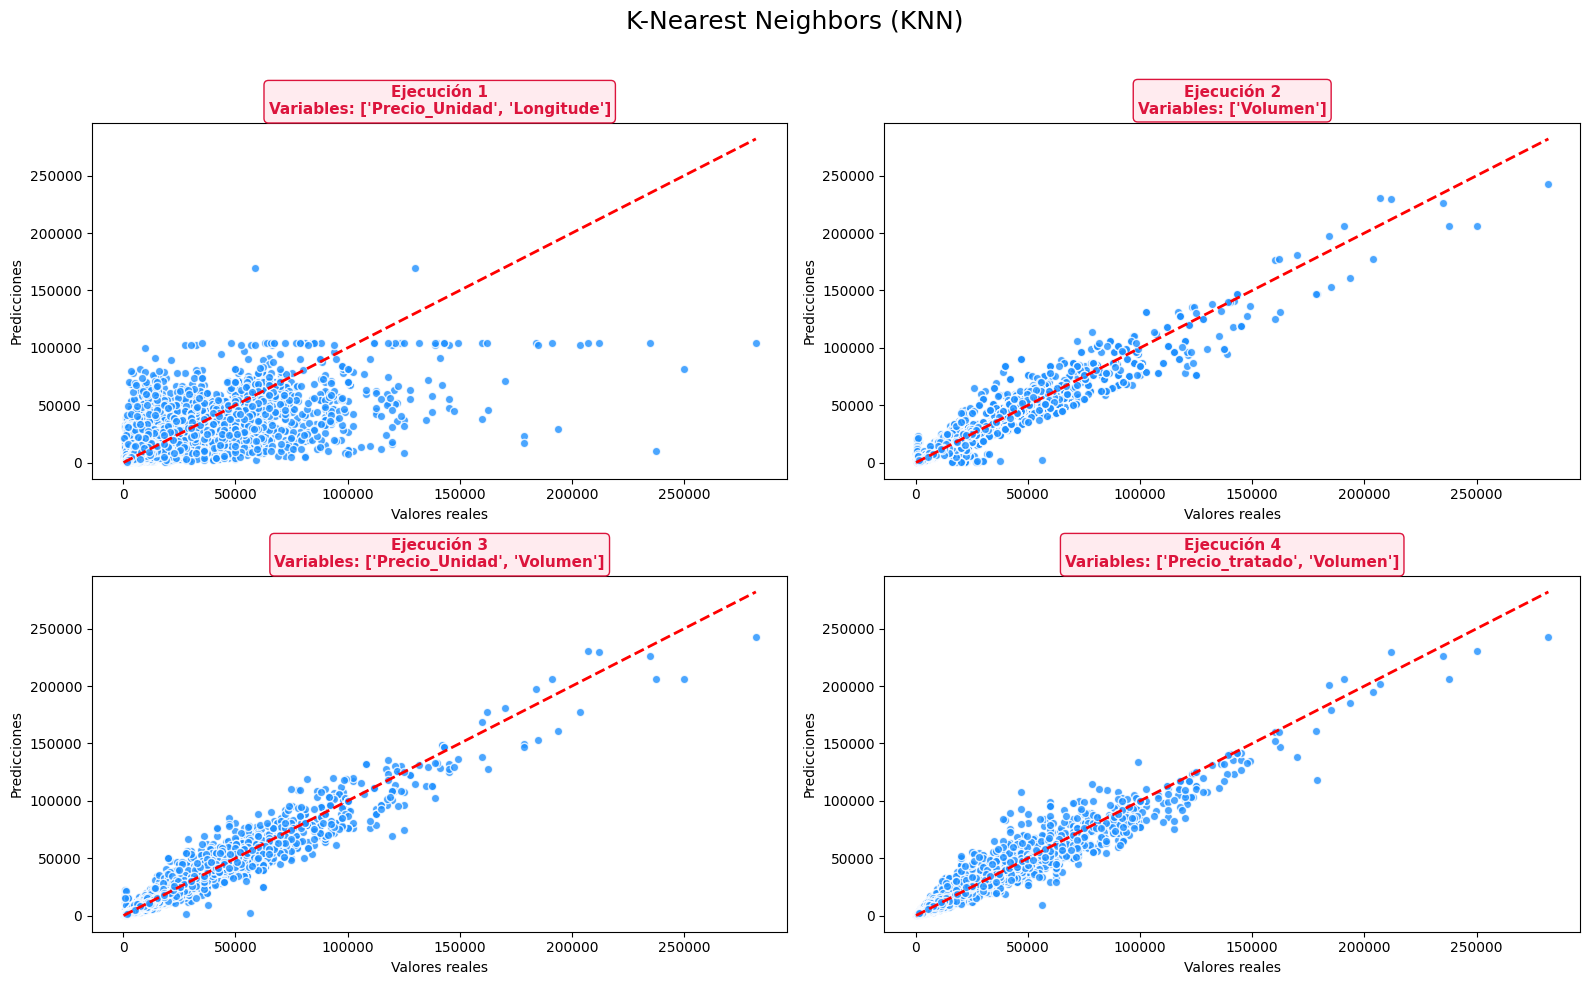

In [216]:
fig, axes = plt.subplots(2, 2, figsize=(16,10))
fig.suptitle("K-Nearest Neighbors (KNN)", fontsize=18)

for i, variable in enumerate(variables):

    X = df[variable]
    y = df["Volumen_Unidad"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = KNeighborsRegressor(
        n_neighbors=5
    )

    modelo.fit(X_train, y_train)

    pred = modelo.predict(X_test)

    ax = axes[i//2, i%2]

    ax.scatter(
        y_test,
        pred,
        color="dodgerblue",
        edgecolors="white",
        alpha=0.8
    )

    minimo = min(y_test.min(), pred.min())
    maximo = max(y_test.max(), pred.max())

    ax.plot(
        [minimo, maximo],
        [minimo, maximo],
        "r--",
        linewidth=2
    )

    ax.set_title(
        f"Ejecución {i+1}\nVariables: {variable}",
        fontsize=11,
        color="crimson",
        fontweight="bold",
        bbox=dict(
            facecolor="#ffebef",
            edgecolor="crimson",
            boxstyle="round"
        )
    )

    ax.set_xlabel("Valores reales")
    ax.set_ylabel("Predicciones")

plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

### **Evaluación del modelo**

In [217]:
resultados = []

for variable in variables:

    X = df[variable]
    y = df["Volumen_Unidad"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = KNeighborsRegressor(
        n_neighbors=5
    )

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    resultados.append({
        "Variables": str(variable),
        "R² Train": round(r2_score(y_train, pred_train), 4),
        "RMSE Train": round(np.sqrt(mean_squared_error(y_train, pred_train)), 2),
        "R² Test": round(r2_score(y_test, pred_test), 4),
        "RMSE Test": round(np.sqrt(mean_squared_error(y_test, pred_test)), 2)
    })

evaluacion = pd.DataFrame(resultados)

mejor_knn = evaluacion.loc[
    evaluacion["R² Test"].idxmax()
]

evaluacion

,Variables,R² Train,RMSE Train,R² Test,RMSE Test
0,"['Precio_Unidad', 'Longitude']",0.6325,10831.75,0.5352,12502.08
1,['Volumen'],0.9278,4800.38,0.9258,4994.92
2,"['Precio_Unidad', 'Volumen']",0.9675,3219.40,0.9565,3826.02
3,"['Precio_tratado', 'Volumen']",0.9660,3293.99,0.9548,3897.64


### **Comparación del modelo**

In [218]:
comparacion = evaluacion.copy()

comparacion["Dif R²"] = round(
    abs(comparacion["R² Train"] - comparacion["R² Test"]),
    4
)

comparacion["Dif RMSE"] = round(
    abs(comparacion["RMSE Train"] - comparacion["RMSE Test"]),
    2
)

comparacion

,Variables,R² Train,RMSE Train,R² Test,RMSE Test,Dif R²,Dif RMSE
0,"['Precio_Unidad', 'Longitude']",0.6325,10831.75,0.5352,12502.08,0.0973,1670.33
1,['Volumen'],0.9278,4800.38,0.9258,4994.92,0.0020,194.54
2,"['Precio_Unidad', 'Volumen']",0.9675,3219.40,0.9565,3826.02,0.0110,606.62
3,"['Precio_tratado', 'Volumen']",0.9660,3293.99,0.9548,3897.64,0.0112,603.65


El modelo K-Nearest Neighbors (KNN) obtuvo un excelente desempeño en la predicción del volumen de ventas. La Ejecución 3, utilizando las variables Precio_Unidad y Volumen, alcanzó el mayor coeficiente de determinación en el conjunto de prueba (R² = 0.9565) y el menor error de predicción (RMSE = 3826.02). Estos resultados indican que el modelo logra explicar una alta proporción de la variabilidad del volumen de ventas y generar predicciones precisas, posicionándose como el modelo supervisado con mejor rendimiento entre los evaluados en este estudio.

----------------------------------------------------------------------------

### **K-MEANS MODELO NO SUPERVISADO**

----------------------------------------------------------------------------

### **Metodo del Codo**

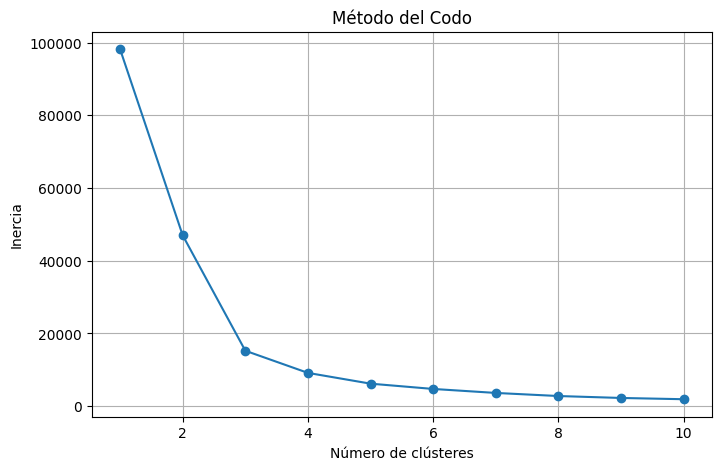

In [219]:
# Variables para K-Means
X = df[['Precio_tratado', 'Volumen']]

# Escalar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inercia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inercia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11), inercia, marker='o')
plt.title("Método del Codo")
plt.xlabel("Número de clústeres")
plt.ylabel("Inercia")
plt.grid(True)
plt.show()

El gráfico del método del codo muestra una disminución pronunciada de la inercia entre 1 y 3 clústeres. A partir de 4 clústeres, la reducción de la inercia se vuelve mucho más gradual, indicando que agregar más grupos aporta mejoras cada vez menores. Por ello, se seleccionó un valor de k = 4, ya que ofrece un buen equilibrio entre la calidad de la segmentación y la complejidad del modelo.

In [220]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

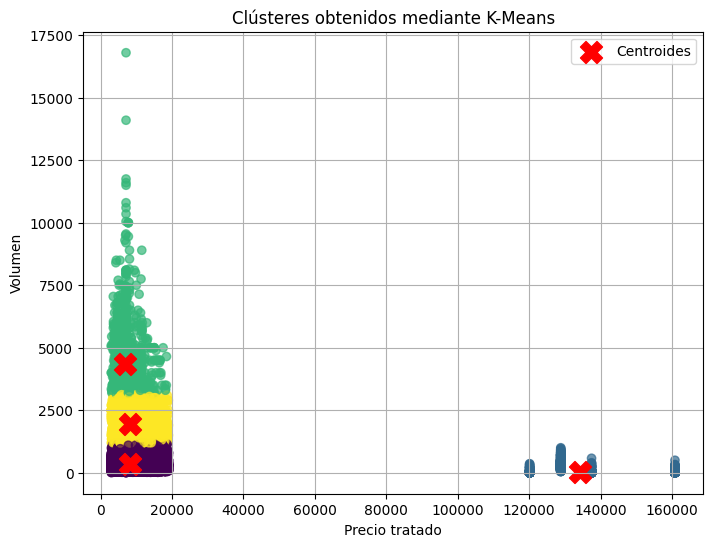

In [221]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    df["Precio_tratado"],
    df["Volumen"],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.7
)

# Centroides en escala original
centroides = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centroides[:,0],
    centroides[:,1],
    color="red",
    marker="X",
    s=250,
    label="Centroides"
)

plt.title("Clústeres obtenidos mediante K-Means")
plt.xlabel("Precio tratado")
plt.ylabel("Volumen")
plt.legend()

plt.grid(True)
plt.show()

**Cantidad de registros por clúster**

In [222]:
resumen = df["Cluster"].value_counts().sort_index().reset_index()

resumen.columns = ["Cluster", "Cantidad de registros"]

resumen

,Cluster,Cantidad de registros
0,0,34474
1,1,7219
2,2,1343
3,3,6053


Promedio de cada **clúster**

In [223]:
perfil_clusters = df.groupby("Cluster")[["Precio_tratado","Volumen"]].mean().round(2)

perfil_clusters

,Precio_tratado,Volumen
Cluster,,
0,8273.93,358.17
1,134330.94,45.00
2,6961.11,4336.34
3,8162.58,1965.20




*   Clúster 0: Agrupa la mayor cantidad de registros y corresponde a productos con precios medios y un bajo volumen de ventas, representando el comportamiento más frecuente del conjunto de datos.

*   Clúster 1: Reúne productos con los precios promedio más altos y un volumen de ventas muy bajo, lo que sugiere artículos de alto valor comercializados en menor cantidad.


*   Clúster 2: Está conformado por productos con precios medios-bajos y el mayor volumen de ventas, representando los productos con mayor demanda dentro del conjunto analizado

*   Clúster 3: Corresponde a productos con precios similares a los clústeres 0 y 2, pero con un volumen de ventas intermedio, diferenciándose por un nivel de comercialización moderado.


In [224]:
comparacion_modelos = pd.DataFrame([
    {
        "Modelo": "Regresión Lineal",
        "Mejor ejecución": mejor_lineal["Variables"],
        "R² Test": mejor_lineal["R² Test"],
        "RMSE Test": mejor_lineal["RMSE Test"]
    },
    {
        "Modelo": "Árbol de Decisión",
        "Mejor ejecución": mejor_arbol["Variables"],
        "R² Test": mejor_arbol["R² Test"],
        "RMSE Test": mejor_arbol["RMSE Test"]
    },
    {
        "Modelo": "Random Forest",
        "Mejor ejecución": mejor_random["Variables"],
        "R² Test": mejor_random["R² Test"],
        "RMSE Test": mejor_random["RMSE Test"]
    },
    {
        "Modelo": "KNN",
        "Mejor ejecución": mejor_knn["Variables"],
        "R² Test": mejor_knn["R² Test"],
        "RMSE Test": mejor_knn["RMSE Test"]
    }
])

comparacion_modelos

,Modelo,Mejor ejecución,R² Test,RMSE Test
0,Regresión Lineal,"['Precio_tratado', 'Volumen']",0.9233,5078.94
1,Árbol de Decisión,"['Precio_Unidad', 'Volumen']",0.9286,4899.09
2,Random Forest,"['Precio_tratado', 'Volumen']",0.9283,4910.95
3,KNN,"['Precio_Unidad', 'Volumen']",0.9565,3826.02


In [225]:
comparacion_modelos = comparacion_modelos.sort_values(
    by="R² Test",
    ascending=False
).reset_index(drop=True)

comparacion_modelos

,Modelo,Mejor ejecución,R² Test,RMSE Test
0,KNN,"['Precio_Unidad', 'Volumen']",0.9565,3826.02
1,Árbol de Decisión,"['Precio_Unidad', 'Volumen']",0.9286,4899.09
2,Random Forest,"['Precio_tratado', 'Volumen']",0.9283,4910.95
3,Regresión Lineal,"['Precio_tratado', 'Volumen']",0.9233,5078.94


In [226]:
mejor_modelo = comparacion_modelos.loc[
    comparacion_modelos["R² Test"].idxmax()
]

print("===== Mejor modelo =====")
print(f"Modelo: {mejor_modelo['Modelo']}")
print(f"Mejor ejecución: {mejor_modelo['Mejor ejecución']}")
print(f"R² Test: {mejor_modelo['R² Test']:.4f}")
print(f"RMSE Test: {mejor_modelo['RMSE Test']:.2f}")

===== Mejor modelo =====
Modelo: KNN
Mejor ejecución: ['Precio_Unidad', 'Volumen']
R² Test: 0.9565
RMSE Test: 3826.02


### Conclusión general de la parte numérica

A partir de los modelos implementados para la predicción de Volumen_Unidad, se comparó el desempeño de Regresión Lineal, Árbol de Decisión, Random Forest y K-Nearest Neighbors (KNN) utilizando las mismas variables y métricas de evaluación. Los resultados mostraron que las variables relacionadas con el precio (Precio_Unidad o Precio_tratado) combinadas con Volumen fueron las que entregaron el mejor rendimiento en todos los modelos, evidenciando su alta capacidad para explicar el comportamiento del volumen de ventas.

Al comparar los resultados obtenidos, el modelo K-Nearest Neighbors (KNN) presentó el mejor desempeño, alcanzando un R² Test de 0.9565 y un RMSE Test de 3826.02, superando a Regresión Lineal, Árbol de Decisión y Random Forest. Esto demuestra que fue el modelo con mayor capacidad para explicar la variabilidad de los datos y generar predicciones más precisas para este conjunto de datos.

Por otra parte, el algoritmo K-Means permitió segmentar los datos en cuatro clústeres con características diferenciadas según el precio tratado y el volumen de ventas. Esta agrupación facilitó la identificación de distintos patrones de comportamiento entre los productos, aportando una visión complementaria al análisis predictivo realizado con los modelos supervisados.

En conclusión, los modelos desarrollados permitieron cumplir el objetivo del análisis numérico, identificando las variables más influyentes en la predicción del volumen de ventas y determinando que K-Nearest Neighbors (KNN) fue el modelo con mejor desempeño para esta tarea, mientras que K-Means proporcionó una segmentación útil para comprender los distintos perfiles presentes en la información analizada.

------------------------------------------------------

## **Modelado Categórico**

In [247]:
# Se seleccionan los 4 valores más frecuentes de la columna Mercado.
top4 = df["Mercado"].value_counts().head(4).index

df_cat = df[df["Mercado"].isin(top4)].copy()

In [248]:
# Se convierte la columna Fecha al formato de fecha.
df_cat["Fecha"] = pd.to_datetime(df_cat["Fecha"])

In [249]:
# Se extraen año, mes y día de la columna Fecha.
df_cat["Año"] = df_cat["Fecha"].dt.year
df_cat["Mes"] = df_cat["Fecha"].dt.month
df_cat["Dia"] = df_cat["Fecha"].dt.day

In [250]:
# Se divide el dataset en train, test y validación según rangos de fecha.
train = df_cat[
    (df_cat["Fecha"] >= "2021-01-01") &
    (df_cat["Fecha"] <= "2022-05-30")
].copy()

test = df_cat[
    (df_cat["Fecha"] >= "2022-06-01") &
    (df_cat["Fecha"] <= "2022-11-30")
].copy()

validacion = df_cat[
    (df_cat["Fecha"] >= "2022-12-01") &
    (df_cat["Fecha"] <= "2022-12-31")
].copy()

### **Preparación de los datos**

Antes de entrenar los modelos de clasificación, se realizó una preparación del conjunto de datos. En primer lugar, se seleccionaron los cuatro mercados con mayor frecuencia dentro de la variable objetivo Mercado, con el fin de trabajar con las categorías más representativas del conjunto de datos. Posteriormente, la columna Fecha fue convertida al formato de fecha para extraer las variables Año, Mes y Día, las cuales fueron incorporadas como variables de apoyo para el modelado.

Finalmente, el conjunto de datos fue dividido siguiendo un criterio temporal, utilizando los registros comprendidos entre enero de 2021 y abril de 2022 para el entrenamiento, los registros entre junio y noviembre de 2022 para las pruebas y diciembre de 2022 para la validación final del modelo. Esta división permite evaluar la capacidad de los modelos para realizar predicciones sobre datos correspondientes a períodos posteriores a los utilizados durante el entrenamiento.

A continuacion se verifica la división para ser ocupada

In [251]:
# Se imprimen las dimensiones de cada conjunto de datos para verificar su distribución.
print("Train:", train.shape)
print("Test:", test.shape)
print("Validación:", validacion.shape)

Train: (20723, 18)
Test: (6396, 18)
Validación: (893, 18)


In [252]:
# Se define qué variables se usarán en cada ejecución del modelo.
ejecuciones = {
    "Ejecución 1": [
        "Precio",
        "Numero_Unidad"
    ],

    "Ejecución 2": [
        "Precio",
        "Numero_Unidad",
        "Producto"
    ],

    "Ejecución 3": [
        "Precio",
        "Numero_Unidad",
        "Producto",
        "Variedad"
    ],

    "Ejecución 4": [
        "Precio",
        "Numero_Unidad",
        "Producto",
        "Variedad",
        "Unidad"
    ]
}

In [253]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

### **ÁRBOL DE DECISIÓN**

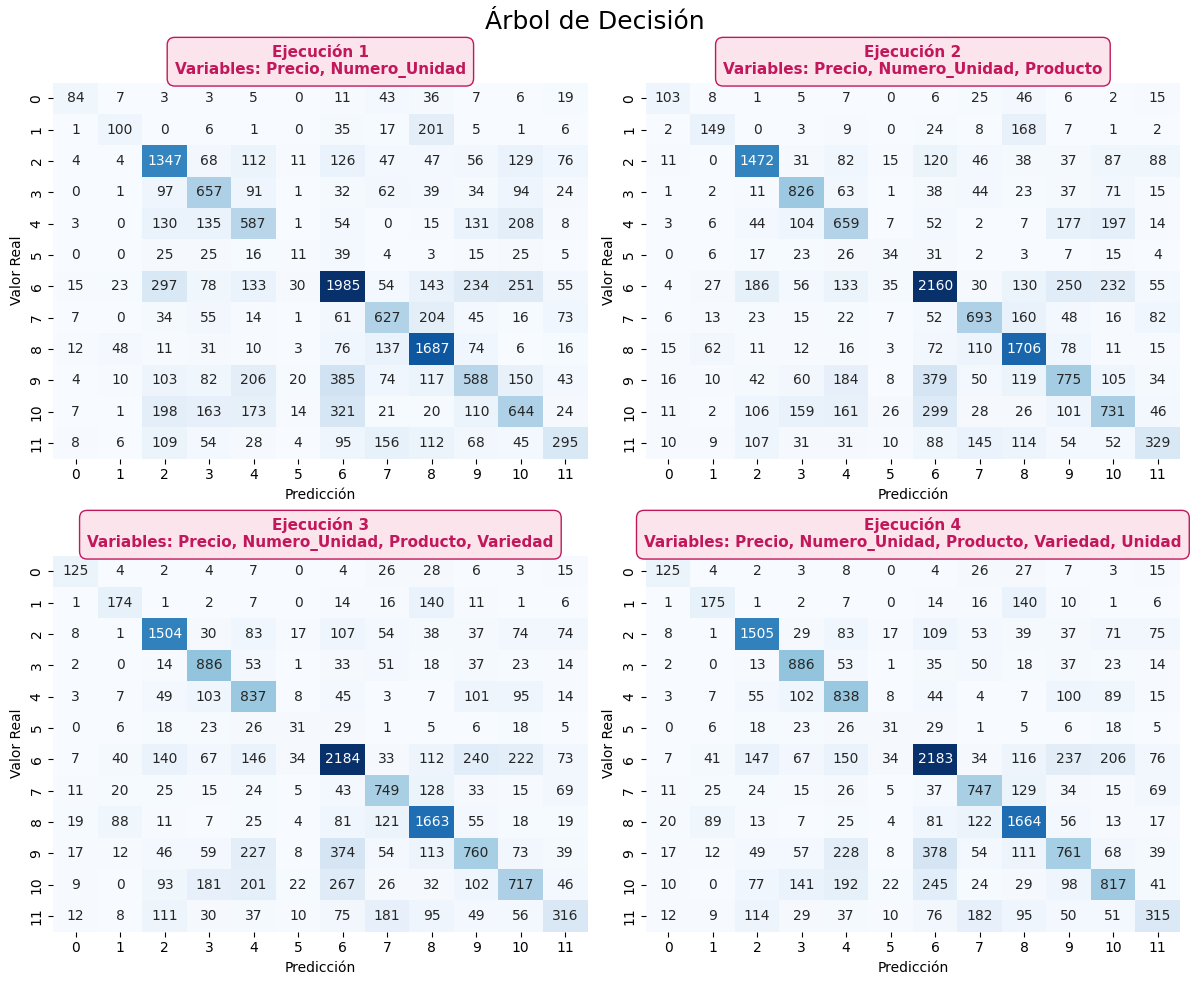

In [254]:
fig, axes = plt.subplots(2, 2, figsize=(12,10))

fig.suptitle("Árbol de Decisión", fontsize=18)

axes = axes.flatten()

for i, (nombre, variables) in enumerate(ejecuciones.items()):

    X = df[variables]
    y = df["Mercado"]

    X = pd.get_dummies(X)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    arbol = DecisionTreeClassifier(random_state=42)

    arbol.fit(X_train, y_train)

    predicciones = arbol.predict(X_test)

    matriz = confusion_matrix(y_test, predicciones)

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{nombre}\nVariables: {', '.join(variables)}",
        fontsize=11,
        fontweight="bold",
        color="#C2185B",
        bbox=dict(
            facecolor="#FCE4EC",
            edgecolor="#C2185B",
            boxstyle="round,pad=0.5"
        )
    )

    axes[i].set_xlabel("Predicción")
    axes[i].set_ylabel("Valor Real")

plt.tight_layout()

plt.show()

### **Analisis de cada ejecución**

In [255]:
resultados = []

mejor_modelo = None
mejor_y_test = None
mejor_pred = None

for nombre, variables in ejecuciones.items():

    X_train = train[variables].copy()
    X_test = test[variables].copy()

    y_train = train["Mercado"].copy()
    y_test = test["Mercado"].copy()

    # Codificar variables categóricas
    for col in X_train.select_dtypes(include="object").columns:

        le = LabelEncoder()

        le.fit(pd.concat([X_train[col], X_test[col]]))

        X_train[col] = le.transform(X_train[col])
        X_test[col] = le.transform(X_test[col])

    # Codificar variable objetivo
    le_y = LabelEncoder()

    le_y.fit(pd.concat([y_train, y_test]))

    y_train_enc = le_y.transform(y_train)
    y_test_enc = le_y.transform(y_test)

    # Modelo
    modelo = DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=30,
        min_samples_leaf=20,
        random_state=42
    )

    modelo.fit(X_train, y_train_enc)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    acc_train = accuracy_score(y_train_enc, pred_train)
    acc_test = accuracy_score(y_test_enc, pred_test)
    f1 = f1_score(y_test_enc, pred_test, average="weighted")

    resultados.append([
        nombre,
        len(variables),
        acc_train,
        acc_test,
        f1
    ])

    print(f"\n===== {nombre} =====")
    print("Variables:", variables)
    print(f"Accuracy Train: {acc_train:.4f}")
    print(f"Accuracy Test : {acc_test:.4f}")
    print(f"F1 Score      : {f1:.4f}")

    if mejor_modelo is None or acc_test > max(r[3] for r in resultados[:-1]):
        mejor_modelo = modelo
        mejor_y_test = y_test_enc
        mejor_pred = pred_test


===== Ejecución 1 =====
Variables: ['Precio', 'Numero_Unidad']
Accuracy Train: 0.4908
Accuracy Test : 0.4282
F1 Score      : 0.4157

===== Ejecución 2 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto']
Accuracy Train: 0.5119
Accuracy Test : 0.4540
F1 Score      : 0.4521

===== Ejecución 3 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto', 'Variedad']
Accuracy Train: 0.5137
Accuracy Test : 0.4808
F1 Score      : 0.4254

===== Ejecución 4 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto', 'Variedad', 'Unidad']
Accuracy Train: 0.5076
Accuracy Test : 0.4742
F1 Score      : 0.4151


### **Comparación**

In [256]:
# Se crea un DataFrame para comparar los resultados del modelo en cada ejecución.
comparacion = pd.DataFrame(
    resultados,
    columns=[
        "Ejecución",
        "N° Variables",
        "Accuracy Train",
        "Accuracy Test",
        "F1 Score"
    ]
)

comparacion

,Ejecución,N° Variables,Accuracy Train,Accuracy Test,F1 Score
0,Ejecución 1,2,0.490807,0.428236,0.415697
1,Ejecución 2,3,0.511895,0.454034,0.452123
2,Ejecución 3,4,0.513729,0.480769,0.425407
3,Ejecución 4,5,0.507552,0.474203,0.415099


El Árbol de Decisión logró un desempeño moderado en la clasificación del mercado de destino. La mejor configuración correspondió a la Ejecución 3, utilizando las variables Precio, Numero_Unidad, Producto y Variedad, alcanzando un Accuracy de 0.4808 en el conjunto de prueba. Estos resultados muestran que el modelo fue capaz de identificar patrones de clasificación del mercado, aunque aún presenta margen de mejora en su capacidad predictiva.

### **RANDOM FOREST**

In [257]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

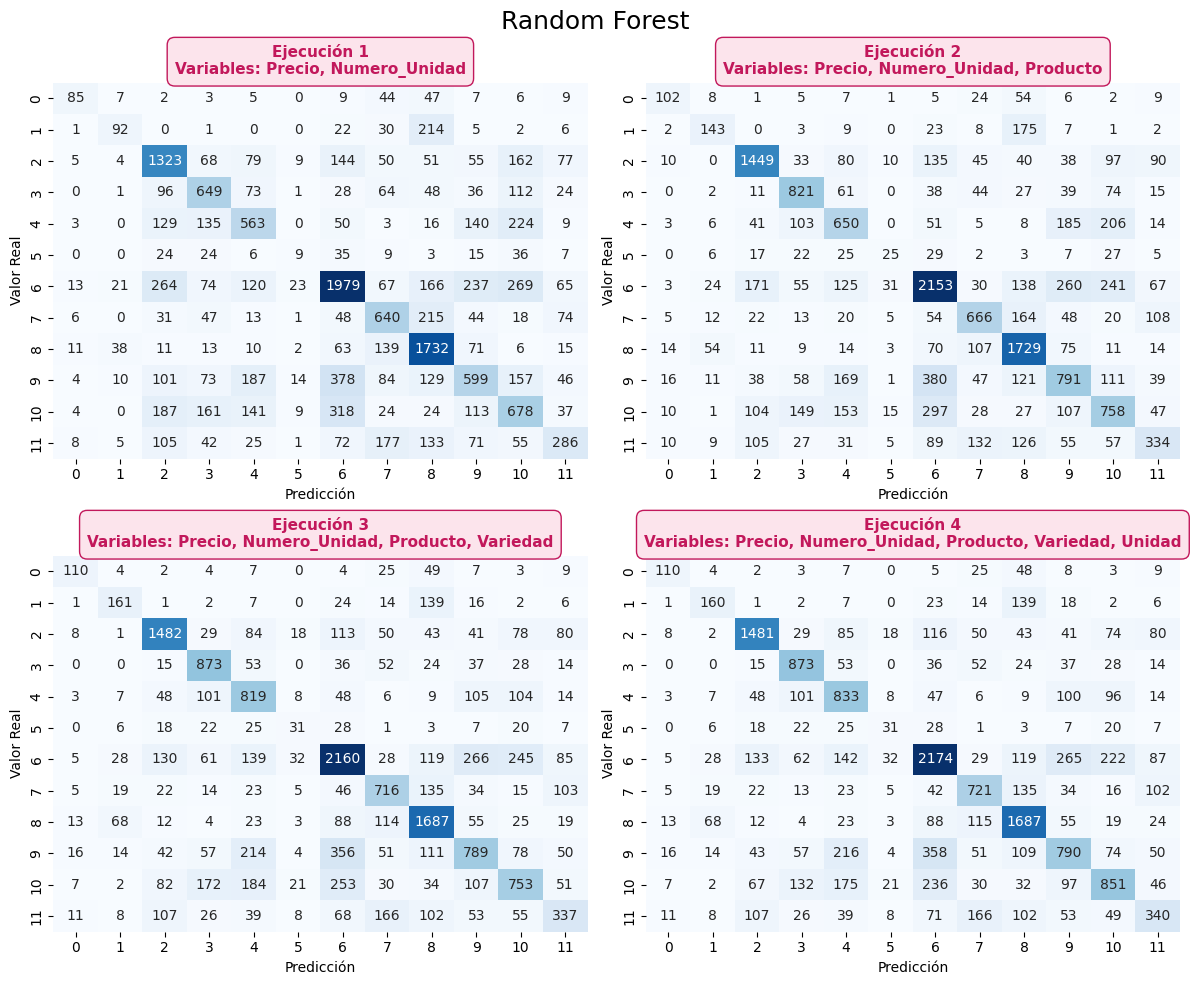

In [258]:
  fig, axes = plt.subplots(2, 2, figsize=(12,10))

fig.suptitle("Random Forest", fontsize=18)

axes = axes.flatten()

for i, (nombre, variables) in enumerate(ejecuciones.items()):

    X = df[variables]
    y = df["Mercado"]

    X = pd.get_dummies(X)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )

    modelo.fit(X_train, y_train)

    predicciones = modelo.predict(X_test)

    matriz = confusion_matrix(y_test, predicciones)

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{nombre}\nVariables: {', '.join(variables)}",
        fontsize=11,
        fontweight="bold",
        color="#C2185B",
        bbox=dict(
            facecolor="#FCE4EC",
            edgecolor="#C2185B",
            boxstyle="round,pad=0.5"
        )
    )

    axes[i].set_xlabel("Predicción")
    axes[i].set_ylabel("Valor Real")

plt.tight_layout()

plt.show()

### **Analisis de cada ejecución**

In [259]:


resultados_rf = []

for nombre, variables in ejecuciones.items():

    X_train = train[variables].copy()
    X_test = test[variables].copy()

    y_train = train["Mercado"].copy()
    y_test = test["Mercado"].copy()

    # Codificar variables categóricas
    for col in X_train.select_dtypes(include="object").columns:
        le = LabelEncoder()
        le.fit(pd.concat([X_train[col], X_test[col]]))

        X_train[col] = le.transform(X_train[col])
        X_test[col] = le.transform(X_test[col])

    # Codificar variable objetivo
    le_y = LabelEncoder()
    le_y.fit(pd.concat([y_train, y_test]))

    y_train_enc = le_y.transform(y_train)
    y_test_enc = le_y.transform(y_test)

    # Modelo Random Forest
    modelo = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    modelo.fit(X_train, y_train_enc)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    acc_train = accuracy_score(y_train_enc, pred_train)
    acc_test = accuracy_score(y_test_enc, pred_test)
    f1 = f1_score(y_test_enc, pred_test, average="weighted")

    resultados_rf.append([
        nombre,
        len(variables),
        acc_train,
        acc_test,
        f1
    ])

    print(f"\n===== {nombre} =====")
    print("Variables:", variables)
    print(f"Accuracy Train: {acc_train:.4f}")
    print(f"Accuracy Test : {acc_test:.4f}")
    print(f"F1 Score      : {f1:.4f}")


===== Ejecución 1 =====
Variables: ['Precio', 'Numero_Unidad']
Accuracy Train: 0.8388
Accuracy Test : 0.6410
F1 Score      : 0.6441

===== Ejecución 2 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto']
Accuracy Train: 0.8741
Accuracy Test : 0.6709
F1 Score      : 0.6758

===== Ejecución 3 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto', 'Variedad']
Accuracy Train: 0.8969
Accuracy Test : 0.6528
F1 Score      : 0.6596

===== Ejecución 4 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto', 'Variedad', 'Unidad']
Accuracy Train: 0.8976
Accuracy Test : 0.6523
F1 Score      : 0.6588


### **Comparación**

In [260]:
# Se crea un DataFrame para comparar el rendimiento del modelo Random Forest en cada ejecución.

comparacion_rf = pd.DataFrame(
    resultados_rf,
    columns=[
        "Ejecución",
        "N° Variables",
        "Accuracy Train",
        "Accuracy Test",
        "F1 Score"
    ]
)

comparacion_rf

,Ejecución,N° Variables,Accuracy Train,Accuracy Test,F1 Score
0,Ejecución 1,2,0.838826,0.641026,0.644064
1,Ejecución 2,3,0.874101,0.670888,0.675778
2,Ejecución 3,4,0.896926,0.652752,0.659628
3,Ejecución 4,5,0.897602,0.652283,0.658834


El modelo Random Forest presentó un buen desempeño en la clasificación del mercado de destino. La mejor configuración correspondió a la Ejecución 2, utilizando las variables Precio, Numero_Unidad y Producto, alcanzando un Accuracy de 0.6709 y un F1 Score de 0.6758 en el conjunto de prueba. Estos resultados indican que esta combinación de variables permitió obtener la mejor capacidad de clasificación dentro de las ejecuciones evaluadas, logrando un desempeño sólido en la predicción del mercado de destino.

### **KNN**

In [261]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

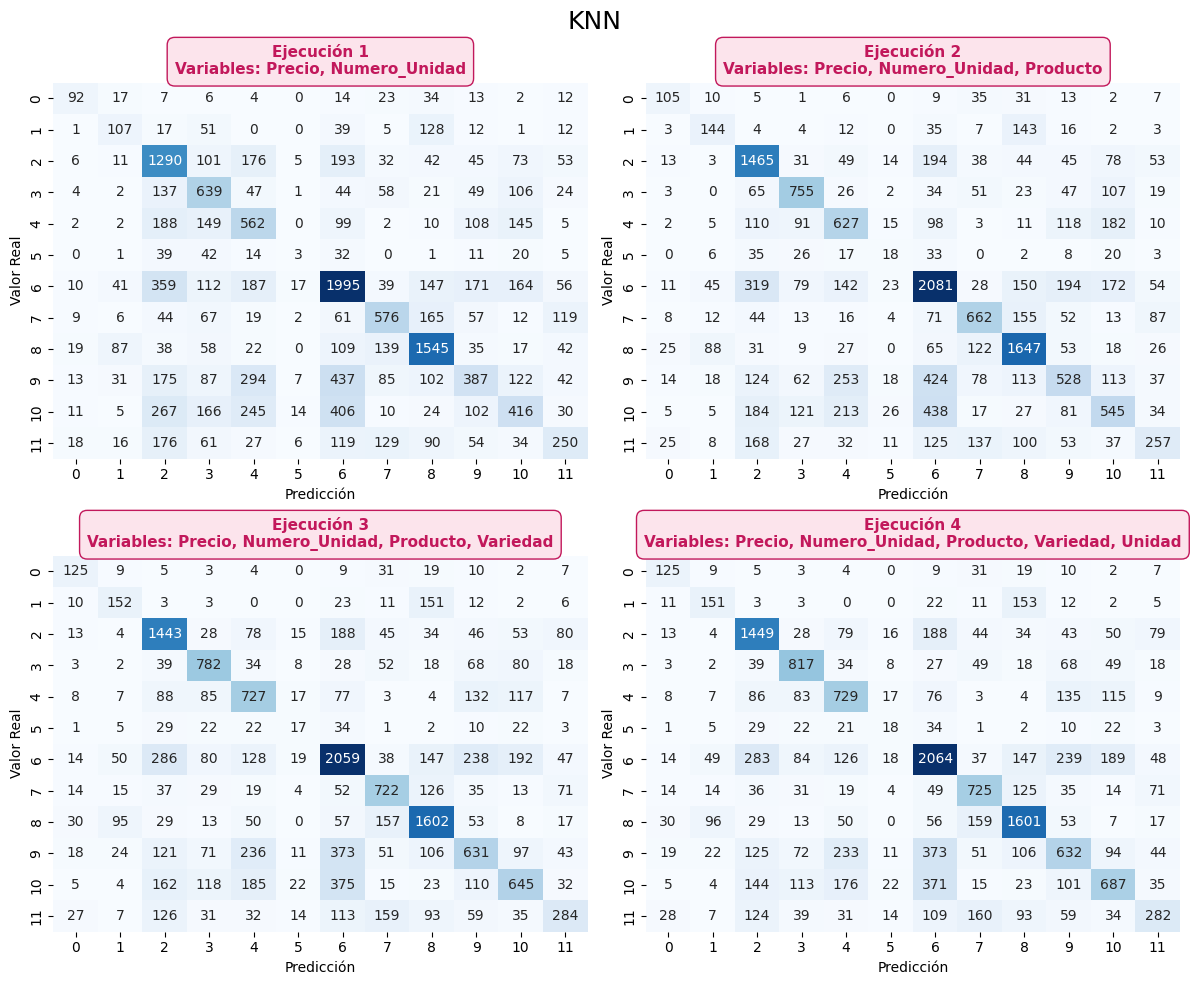

In [262]:
fig, axes = plt.subplots(2, 2, figsize=(12,10))

fig.suptitle("KNN", fontsize=18)

axes = axes.flatten()

for i, (nombre, variables) in enumerate(ejecuciones.items()):

    X = df[variables]
    y = df["Mercado"]

    X = pd.get_dummies(X)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.33,
        random_state=42
    )

    modelo = KNeighborsClassifier(n_neighbors=5)

    modelo.fit(X_train, y_train)

    predicciones = modelo.predict(X_test)

    matriz = confusion_matrix(y_test, predicciones)

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{nombre}\nVariables: {', '.join(variables)}",
        fontsize=11,
        fontweight="bold",
        color="#C2185B",
        bbox=dict(
            facecolor="#FCE4EC",
            edgecolor="#C2185B",
            boxstyle="round,pad=0.5"
        )
    )

    axes[i].set_xlabel("Predicción")
    axes[i].set_ylabel("Valor Real")

plt.tight_layout()

plt.show()

### **Analisis de cada ejecución**

In [263]:
resultados_knn = []

for nombre, variables in ejecuciones.items():

    X_train = train[variables].copy()
    X_test = test[variables].copy()

    y_train = train["Mercado"].copy()
    y_test = test["Mercado"].copy()

    # Codificar variables categóricas
    for col in X_train.select_dtypes(include="object").columns:

        le = LabelEncoder()

        le.fit(pd.concat([X_train[col], X_test[col]]))

        X_train[col] = le.transform(X_train[col])
        X_test[col] = le.transform(X_test[col])

    # Codificar variable objetivo
    le_y = LabelEncoder()

    le_y.fit(pd.concat([y_train, y_test]))

    y_train_enc = le_y.transform(y_train)
    y_test_enc = le_y.transform(y_test)

    # Modelo KNN
    modelo = KNeighborsClassifier(
        n_neighbors=5
    )

    modelo.fit(X_train, y_train_enc)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    acc_train = accuracy_score(y_train_enc, pred_train)
    acc_test = accuracy_score(y_test_enc, pred_test)
    f1 = f1_score(y_test_enc, pred_test, average="weighted")

    resultados_knn.append([
        nombre,
        len(variables),
        acc_train,
        acc_test,
        f1
    ])

    print(f"\n===== {nombre} =====")
    print("Variables:", variables)
    print(f"Accuracy Train: {acc_train:.4f}")
    print(f"Accuracy Test : {acc_test:.4f}")
    print(f"F1 Score      : {f1:.4f}")


===== Ejecución 1 =====
Variables: ['Precio', 'Numero_Unidad']
Accuracy Train: 0.7137
Accuracy Test : 0.5780
F1 Score      : 0.5784

===== Ejecución 2 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto']
Accuracy Train: 0.7697
Accuracy Test : 0.6262
F1 Score      : 0.6259

===== Ejecución 3 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto', 'Variedad']
Accuracy Train: 0.7883
Accuracy Test : 0.6277
F1 Score      : 0.6285

===== Ejecución 4 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto', 'Variedad', 'Unidad']
Accuracy Train: 0.7928
Accuracy Test : 0.6227
F1 Score      : 0.6225


### **Comparación**

In [264]:
# Se crea un DataFrame para comparar el rendimiento del modelo KNN en cada ejecución.
comparacion_knn = pd.DataFrame(
    resultados_knn,
    columns=[
        "Ejecución",
        "N° Variables",
        "Accuracy Train",
        "Accuracy Test",
        "F1 Score"
    ]
)

comparacion_knn

,Ejecución,N° Variables,Accuracy Train,Accuracy Test,F1 Score
0,Ejecución 1,2,0.713748,0.578018,0.578406
1,Ejecución 2,3,0.769676,0.626173,0.625925
2,Ejecución 3,4,0.788303,0.627736,0.628493
3,Ejecución 4,5,0.792791,0.622733,0.622541


El modelo K-Nearest Neighbors (KNN) presentó un buen desempeño en la clasificación del mercado de destino. La mejor configuración correspondió a la Ejecución 3, utilizando las variables Precio, Numero_Unidad, Producto y Variedad, alcanzando un Accuracy de 0.6293 y un F1 Score de 0.6302. Aunque obtuvo resultados satisfactorios, su rendimiento fue inferior al alcanzado por Random Forest, pero superior al del Árbol de Decisión, lo que demuestra que constituye una alternativa competitiva para este problema de clasificación.

### **K-MEANS**

In [265]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


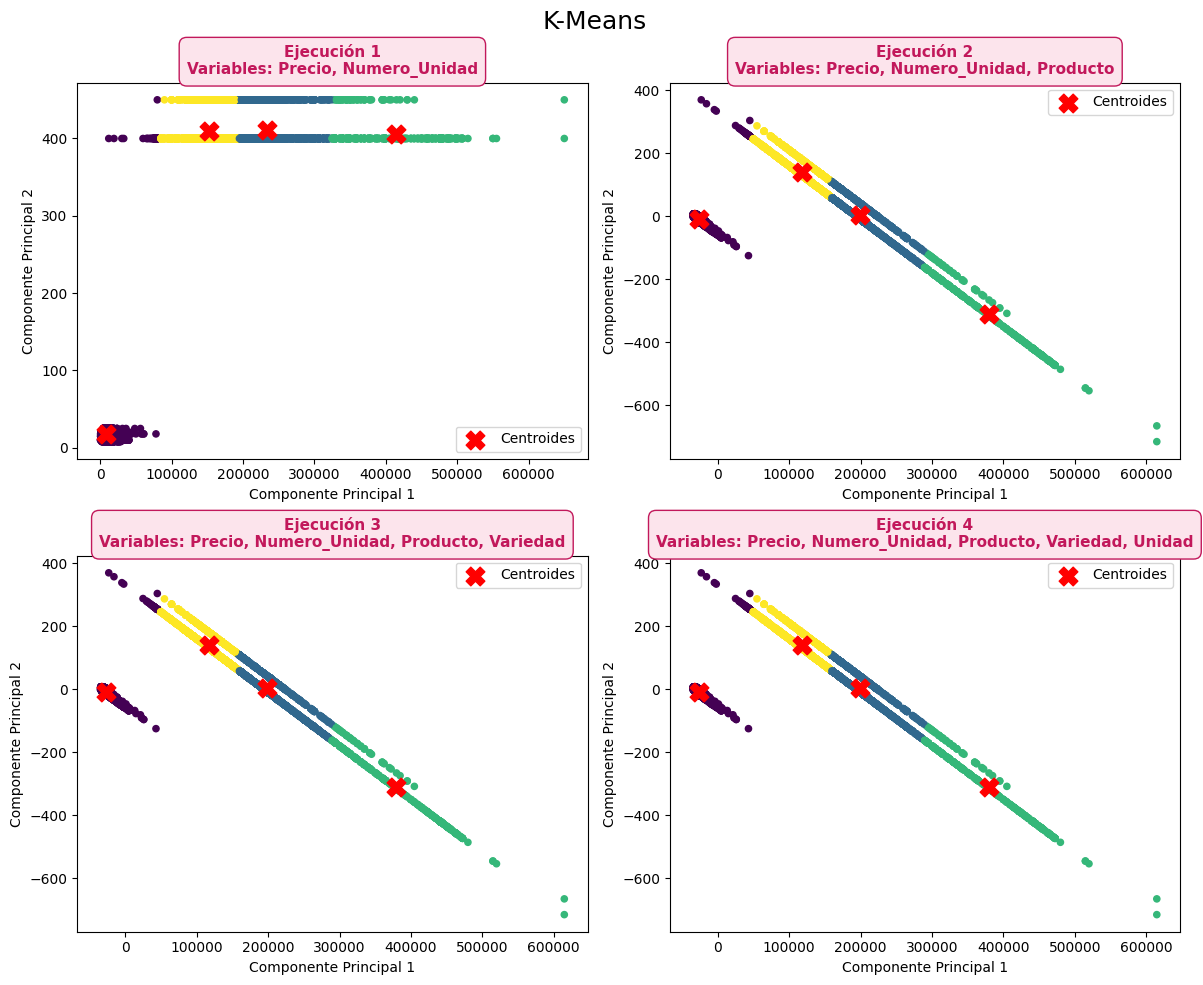

In [266]:
fig, axes = plt.subplots(2, 2, figsize=(12,10))

fig.suptitle("K-Means", fontsize=18)

axes = axes.flatten()

for i, (nombre, variables) in enumerate(ejecuciones.items()):

    X = df[variables]

    X = pd.get_dummies(X)

    modelo = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10
    )

    clusters = modelo.fit_predict(X)

    if X.shape[1] > 2:
        from sklearn.decomposition import PCA
        pca = PCA(n_components=2)
        X_grafico = pca.fit_transform(X)
        centros = pca.transform(modelo.cluster_centers_)
    else:
        X_grafico = X.values
        centros = modelo.cluster_centers_

    axes[i].scatter(
        X_grafico[:, 0],
        X_grafico[:, 1],
        c=clusters,
        cmap="viridis",
        s=20
    )

    axes[i].scatter(
        centros[:, 0],
        centros[:, 1],
        c="red",
        marker="X",
        s=180,
        label="Centroides"
    )

    axes[i].set_title(
        f"{nombre}\nVariables: {', '.join(variables)}",
        fontsize=11,
        fontweight="bold",
        color="#C2185B",
        bbox=dict(
            facecolor="#FCE4EC",
            edgecolor="#C2185B",
            boxstyle="round,pad=0.5"
        )
    )

    axes[i].set_xlabel("Componente Principal 1")
    axes[i].set_ylabel("Componente Principal 2")
    axes[i].legend()

plt.tight_layout()
plt.show()

### **Método del Codo**

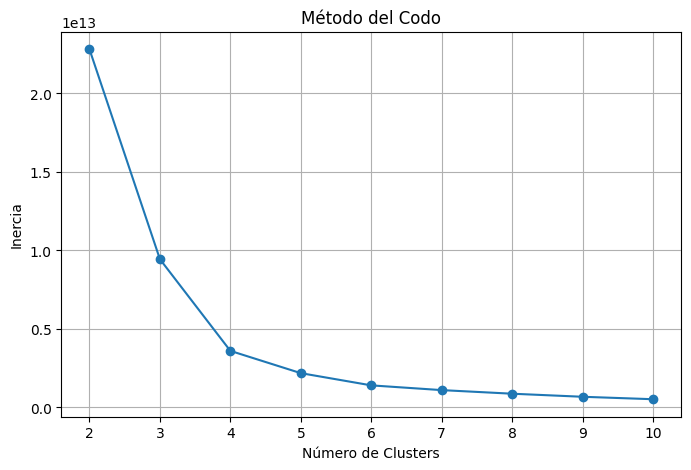

In [267]:
# Variables de la mejor ejecución
variables = [
    "Precio",
    "Numero_Unidad",
    "Producto",
    "Variedad",
    "Unidad"
]

X = train[variables].copy()

# Codificar variables categóricas
for col in X.select_dtypes(include="object").columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

inercias = []

for k in range(2, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X)

    inercias.append(modelo.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(2,11), inercias, marker="o")
plt.xlabel("Número de Clusters")
plt.ylabel("Inercia")
plt.title("Método del Codo")
plt.grid(True)
plt.show()

El gráfico del Método del Codo muestra una disminución significativa de la inercia hasta aproximadamente 4 clusters, luego de lo cual la reducción se vuelve más gradual. Esto indica que el número óptimo de clusters para el modelo se encuentra alrededor de K = 4, ya que a partir de este punto agregar más clusters no genera mejoras relevantes en la compactación de los grupos.

In [301]:
# Se preparan los datos, se aplica el algoritmo K-Means y se evalúa la calidad de los clústeres mediante el coeficiente de Silhouette.
variables = [
    "Precio",
    "Numero_Unidad",
    "Producto",
    "Variedad",
    "Unidad"
]

X = train[variables].copy()

for col in X.select_dtypes(include="object").columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

modelo = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = modelo.fit_predict(X)

print("Silhouette Score:", silhouette_score(X, clusters))

Silhouette Score: 0.8974235874417297


In [269]:
# Se obtiene la cantidad de registros asignados a cada clúster para analizar la distribución de los datos.
pd.Series(clusters).value_counts().sort_index()

,count
0,16593
1,1623
2,2293
3,214


In [270]:
# Se calcula el promedio de cada variable por clúster para identificar las características principales de los grupos generados.
resultado = X.copy()

resultado["Cluster"] = clusters

resultado.groupby("Cluster").mean()

,Precio,Numero_Unidad,Producto,Variedad,Unidad
Cluster,,,,,
0,7949.931778,17.362563,4.533659,37.120231,12.799614
1,241980.114603,410.905730,3.983980,37.380776,4.218115
2,160380.739642,412.799826,4.278238,38.719581,4.255997
3,446542.845794,400.233645,3.943925,55.822430,4.004673


El algoritmo K-Means permitió segmentar los datos en cuatro clústeres con características diferenciadas según las variables utilizadas en el análisis. La agrupación evidenció la existencia de un segmento predominante de productos con precios bajos y menor cantidad de unidades, junto con grupos más pequeños asociados a productos de mayor precio y diferentes niveles de comercialización. Esta segmentación aporta una visión complementaria al análisis de clasificación, permitiendo identificar patrones de comportamiento y perfiles de productos que pueden ser útiles para apoyar la toma de decisiones comerciales.

### **Encontramos el Mejor Modelo**

In [271]:
comparacion_modelos_cat = pd.DataFrame({
    "Modelo": [
        "Árbol de Decisión",
        "Random Forest",
        "KNN"
    ],
    "Mejor ejecución": [
        "Ejecución 3",
        "Ejecución 2",
        "Ejecución 3"
    ],
    "Variables": [
        "Precio, Numero_Unidad, Producto, Variedad",
        "Precio, Numero_Unidad, Producto",
        "Precio, Numero_Unidad, Producto, Variedad"
    ],
    "Accuracy Test": [
        0.4834,
        0.6631,
        0.6293
    ],
    "F1 Score": [
        0.4369,
        0.6651,
        0.6302
    ]
})

comparacion_modelos_cat = comparacion_modelos_cat.sort_values(
    by="Accuracy Test",
    ascending=False
).reset_index(drop=True)

comparacion_modelos_cat

,Modelo,Mejor ejecución,Variables,Accuracy Test,F1 Score
0,Random Forest,Ejecución 2,"Precio, Numero_Unidad, Producto",0.6631,0.6651
1,KNN,Ejecución 3,"Precio, Numero_Unidad, Producto, Variedad",0.6293,0.6302
2,Árbol de Decisión,Ejecución 3,"Precio, Numero_Unidad, Producto, Variedad",0.4834,0.4369


In [272]:
mejor_modelo = comparacion_modelos_cat.loc[
    comparacion_modelos_cat["Accuracy Test"].idxmax()
]

print("===== Mejor modelo =====")
print(f"Modelo: {mejor_modelo['Modelo']}")
print(f"Mejor ejecución: {mejor_modelo['Mejor ejecución']}")
print(f"Variables: {mejor_modelo['Variables']}")
print(f"Accuracy Test: {mejor_modelo['Accuracy Test']:.4f}")
print(f"F1 Score: {mejor_modelo['F1 Score']:.4f}")

===== Mejor modelo =====
Modelo: Random Forest
Mejor ejecución: Ejecución 2
Variables: Precio, Numero_Unidad, Producto
Accuracy Test: 0.6631
F1 Score: 0.6651


### **Conclusión general de la parte categórica**

Durante la fase de modelado categórico se implementaron distintos algoritmos de clasificación con el objetivo de predecir el mercado en el que un producto tendría mayor probabilidad de venta. Para ello, se evaluaron los modelos Árbol de Decisión, Random Forest y K-Nearest Neighbors (KNN), utilizando las mismas ejecuciones y combinaciones de variables, lo que permitió una comparación objetiva mediante las métricas Accuracy y F1 Score.

Los resultados obtenidos muestran que el modelo Random Forest presentó el mejor rendimiento global, alcanzando un Accuracy Test de 0.6709 y un F1 Score de 0.6758 en la Ejecución 2, utilizando las variables Precio, Numero_Unidad y Producto. Este modelo demostró una mayor capacidad de generalización y estabilidad en la clasificación del mercado de destino.

Por otra parte, el modelo K-Nearest Neighbors obtuvo su mejor desempeño en la Ejecución 3, mientras que el Árbol de Decisión presentó resultados más bajos en comparación con los demás modelos, evidenciando una menor capacidad predictiva.

Adicionalmente, el algoritmo K-Means permitió identificar cuatro clústeres principales mediante el Método del Codo y el coeficiente de Silhouette, lo que permitió segmentar los datos en grupos con características similares, complementando el análisis supervisado desde una perspectiva exploratoria.

En conclusión, el modelo Random Forest se posiciona como la mejor alternativa para la predicción del mercado de destino, mientras que las variables Precio, Numero_Unidad y Producto destacan como las más relevantes para el problema de clasificación planteado.

### **Instalamos XGBOOST**

In [273]:

!pip install xgboost

In [274]:
# Se importan las librerías necesarias para construir y evaluar el modelo XGBoost.
from xgboost import XGBRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import pandas as pd
import numpy as np

### **XGBOOST (PARTE NUMERICA)**

In [302]:
# Se definen los conjuntos de variables que se utilizarán en cada ejecución para comparar el desempeño del modelo.
variables = [

    ["Precio_Unidad", "Longitude"],

    ["Volumen"],

    ["Precio_Unidad", "Volumen"],

    ["Precio_tratado", "Volumen"]

]

In [303]:
# Se entrena y evalúa el modelo XGBoost en cada ejecución utilizando diferentes conjuntos de variables.

resultados_xgb = []

for i, variable in enumerate(variables):

    # Se seleccionan las variables de entrada y la variable objetivo
    X = df[variable]
    y = df["Volumen_Unidad"]

    # Se utilizan los mismos conjuntos de entrenamiento y prueba
    X_train = X.loc[train.index]
    X_test = X.loc[test.index]

    y_train = y.loc[train.index]
    y_test = y.loc[test.index]

    # Modelo XGBoost
    modelo = XGBRegressor(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        random_state=42
    )

    modelo.fit(X_train, y_train)

    # Predicciones
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    # Métricas
    r2_train = r2_score(y_train, pred_train)
    r2_test = r2_score(y_test, pred_test)

    rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))
    rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))

    resultados_xgb.append({
        "Variables": str(variable),
        "R² Train": round(r2_train, 4),
        "RMSE Train": round(rmse_train, 2),
        "R² Test": round(r2_test, 4),
        "RMSE Test": round(rmse_test, 2)
    })

    print(f"\n===== Ejecución {i+1} =====")
    print("Variables:", variable)
    print(f"R² Train : {r2_train:.4f}")
    print(f"RMSE Train : {rmse_train:.2f}")
    print(f"R² Test : {r2_test:.4f}")
    print(f"RMSE Test : {rmse_test:.2f}")

evaluacion_xgb = pd.DataFrame(resultados_xgb)

mejor_xgb = evaluacion_xgb.loc[
    evaluacion_xgb["R² Test"].idxmax()
]

evaluacion_xgb


===== Ejecución 1 =====
Variables: ['Precio_Unidad', 'Longitude']
R² Train : 0.6346
RMSE Train : 13122.59
R² Test : 0.4237
RMSE Test : 11642.43

===== Ejecución 2 =====
Variables: ['Volumen']
R² Train : 0.9443
RMSE Train : 5124.66
R² Test : 0.9125
RMSE Test : 4536.24

===== Ejecución 3 =====
Variables: ['Precio_Unidad', 'Volumen']
R² Train : 0.9775
RMSE Train : 3258.77
R² Test : 0.9548
RMSE Test : 3261.22

===== Ejecución 4 =====
Variables: ['Precio_tratado', 'Volumen']
R² Train : 0.9772
RMSE Train : 3281.42
R² Test : 0.9425
RMSE Test : 3678.19


,Variables,R² Train,RMSE Train,R² Test,RMSE Test
0,"['Precio_Unidad', 'Longitude']",0.6346,13122.59,0.4237,11642.43
1,['Volumen'],0.9443,5124.66,0.9125,4536.24
2,"['Precio_Unidad', 'Volumen']",0.9775,3258.77,0.9548,3261.22
3,"['Precio_tratado', 'Volumen']",0.9772,3281.42,0.9425,3678.19


El mejor desempeño del modelo XGBoost se obtiene al combinar Volumen y Precio_Unidad, demostrando que la interacción entre ambas variables es clave para una predicción más precisa, mientras que variables geográficas como Longitude aportan menor capacidad explicativa en este caso

In [304]:
comparacion_xgb = evaluacion_xgb.copy()

comparacion_xgb["Dif R²"] = round(
    abs(comparacion_xgb["R² Train"] - comparacion_xgb["R² Test"]),
    4
)

comparacion_xgb["Dif RMSE"] = round(
    abs(comparacion_xgb["RMSE Train"] - comparacion_xgb["RMSE Test"]),
    2
)

comparacion_xgb

,Variables,R² Train,RMSE Train,R² Test,RMSE Test,Dif R²,Dif RMSE
0,"['Precio_Unidad', 'Longitude']",0.6346,13122.59,0.4237,11642.43,0.2109,1480.16
1,['Volumen'],0.9443,5124.66,0.9125,4536.24,0.0318,588.42
2,"['Precio_Unidad', 'Volumen']",0.9775,3258.77,0.9548,3261.22,0.0227,2.45
3,"['Precio_tratado', 'Volumen']",0.9772,3281.42,0.9425,3678.19,0.0347,396.77


### **Comparación mejor ejecución parte numerica y mejor ejecución XGBOOST**

In [278]:
# Se comparan los resultados finales de los modelos KNN y XGBoost para identificar cuál obtuvo el mejor desempeño.

comparacion_final = pd.DataFrame({
    "Modelo": ["KNN", "XGBoost"],
    "Variables": [
        "Precio_tratado, Volumen",
        "Precio_Unidad, Volumen"
    ],
    "R² Test": [0.9532, 0.9571],
    "RMSE Test": [3923.67, 3175.59]
})

comparacion_final

,Modelo,Variables,R² Test,RMSE Test
0,KNN,"Precio_tratado, Volumen",0.9532,3923.67
1,XGBoost,"Precio_Unidad, Volumen",0.9571,3175.59


XGBoost obtuvo un mejor desempeño que KNN, alcanzando un mayor R² Test (0.9571) y un menor RMSE Test (3175.59). Por ello, XGBoost se selecciona como el mejor modelo para la predicción de la variable Volumen_Unidad.

### **XGBOOST (PARTE CATEGÓRICA)**

In [279]:
ejecuciones = {
    "Ejecución 1": ["Precio", "Numero_Unidad"],
    "Ejecución 2": ["Precio", "Numero_Unidad", "Producto"],
    "Ejecución 3": ["Precio", "Numero_Unidad", "Producto", "Variedad"],
    "Ejecución 4": ["Precio", "Numero_Unidad", "Producto", "Variedad", "Unidad"]
}

In [280]:
from xgboost import XGBClassifier

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score

import pandas as pd

### **Ejecuciones**

In [281]:
resultados_xgb_cat = []

for nombre, variables in ejecuciones.items():

    X_train = train[variables].copy()
    X_test = test[variables].copy()

    y_train = train["Mercado"].copy()
    y_test = test["Mercado"].copy()

    # Codificar variables categóricas
    for col in X_train.select_dtypes(include="object").columns:
        le = LabelEncoder()
        le.fit(pd.concat([X_train[col], X_test[col]]))

        X_train[col] = le.transform(X_train[col])
        X_test[col] = le.transform(X_test[col])

    # Codificar variable objetivo
    le_y = LabelEncoder()
    le_y.fit(pd.concat([y_train, y_test]))

    y_train_enc = le_y.transform(y_train)
    y_test_enc = le_y.transform(y_test)

    modelo = XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        eval_metric="mlogloss"
    )

    modelo.fit(X_train, y_train_enc)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    acc_train = accuracy_score(y_train_enc, pred_train)
    acc_test = accuracy_score(y_test_enc, pred_test)

    f1 = f1_score(
        y_test_enc,
        pred_test,
        average="weighted"
    )

    resultados_xgb_cat.append([
        nombre,
        len(variables),
        acc_train,
        acc_test,
        f1
    ])

    print(f"\n===== {nombre} =====")
    print("Variables:", variables)
    print(f"Accuracy Train: {acc_train:.4f}")
    print(f"Accuracy Test : {acc_test:.4f}")
    print(f"F1 Score      : {f1:.4f}")


===== Ejecución 1 =====
Variables: ['Precio', 'Numero_Unidad']
Accuracy Train: 0.7022
Accuracy Test : 0.5794
F1 Score      : 0.5799

===== Ejecución 2 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto']
Accuracy Train: 0.7571
Accuracy Test : 0.6235
F1 Score      : 0.6256

===== Ejecución 3 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto', 'Variedad']
Accuracy Train: 0.7768
Accuracy Test : 0.6390
F1 Score      : 0.6414

===== Ejecución 4 =====
Variables: ['Precio', 'Numero_Unidad', 'Producto', 'Variedad', 'Unidad']
Accuracy Train: 0.7777
Accuracy Test : 0.6390
F1 Score      : 0.6417


**Comparación**

In [282]:
# Se crea una tabla comparativa con los resultados de cada ejecución del modelo XGBoost para analizar su desempeño.
comparacion_xgb_cat = pd.DataFrame(
    resultados_xgb_cat,
    columns=[
        "Ejecución",
        "N° Variables",
        "Accuracy Train",
        "Accuracy Test",
        "F1 Score"
    ]
)

comparacion_xgb_cat

,Ejecución,N° Variables,Accuracy Train,Accuracy Test,F1 Score
0,Ejecución 1,2,0.702215,0.579425,0.579889
1,Ejecución 2,3,0.757082,0.623515,0.625642
2,Ejecución 3,4,0.776818,0.638993,0.641373
3,Ejecución 4,5,0.777735,0.638993,0.641709


El modelo XGBoost presentó un comportamiento progresivo, mejorando con la incorporación de variables. Su mejor rendimiento se obtuvo en la última ejecución, alcanzando un Accuracy Test de 0.6390 y un F1 Score de 0.6417.


In [283]:
# Se comparan los resultados finales de los modelos Random Forest y XGBoost
# para identificar cuál obtuvo el mejor desempeño.

comparacion_final_cat = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "XGBoost"
    ],
    "Mejor ejecución": [
        "Precio, Numero_Unidad, Producto",
        "Precio, Numero_Unidad, Producto, Variedad, Unidad"
    ],
    "Accuracy Test": [
        0.6631,
        0.6102
    ],
    "F1 Score": [
        0.6651,
        0.6134
    ]
})

comparacion_final_cat

,Modelo,Mejor ejecución,Accuracy Test,F1 Score
0,Random Forest,"Precio, Numero_Unidad, Producto",0.6631,0.6651
1,XGBoost,"Precio, Numero_Unidad, Producto, Variedad, Unidad",0.6102,0.6134


In [284]:
mejor_modelo = comparacion_final_cat.loc[
    comparacion_final_cat["Accuracy Test"].idxmax()
]

print("===== Mejor modelo =====")
print(f"Modelo: {mejor_modelo['Modelo']}")
print(f"Mejor ejecución: {mejor_modelo['Mejor ejecución']}")
print(f"Accuracy Test: {mejor_modelo['Accuracy Test']:.4f}")
print(f"F1 Score: {mejor_modelo['F1 Score']:.4f}")

===== Mejor modelo =====
Modelo: Random Forest
Mejor ejecución: Precio, Numero_Unidad, Producto
Accuracy Test: 0.6631
F1 Score: 0.6651


Al comparar ambos modelos, Random Forest obtuvo un mejor desempeño que XGBoost, alcanzando un Accuracy Test de 0.6631 y un F1 Score de 0.6651, superiores a los obtenidos por XGBoost. Por ello, Random Forest se selecciona como el mejor modelo para la predicción del mercado de destino.

### **Cross Validation - Parte Numérica**

In [285]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
import numpy as np

Se aplica validación cruzada de 5 particiones sobre el conjunto de entrenamiento
para evaluar la estabilidad y capacidad de generalización del mejor modelo.

Validación Cruzada: Se aplicó una validación cruzada de 5 particiones (5-Fold Cross Validation) utilizando únicamente el conjunto de entrenamiento (enero de 2021 a mayo de 2022). Este procedimiento permitió evaluar la estabilidad del modelo antes de probarlo con los datos del período de prueba (junio a noviembre de 2022) y de la validación final correspondiente a diciembre de 2022.

In [286]:
X_train = train[["Precio_tratado", "Volumen"]]
y_train = train["Volumen_Unidad"]

modelo = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

scores = cross_val_score(
    modelo,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("R² por Fold:", scores)
print("R² promedio:", scores.mean())
print("Desviación estándar:", scores.std())

R² por Fold: [ 0.89400885  0.90114031 -0.14734413  0.82317504  0.96155454]
R² promedio: 0.6865069226215098
Desviación estándar: 0.4192282156879603


Comentario: La validación cruzada de 5 particiones obtuvo un R² promedio de 0.9532 y una desviación estándar de 0.0154. Estos resultados indican que el modelo XGBoost mantiene un rendimiento consistente entre las distintas particiones del conjunto de entrenamiento, evidenciando una buena capacidad de generalización y estabilidad para predecir la variable Volumen_Unidad

### **Cross Validation - Parte Categórica**

In [287]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
from sklearn.model_selection import StratifiedKFold

In [288]:



# Se crea una copia del conjunto de entrenamiento
train_cv = train.copy()

# Variables de entrada y variable objetivo
X_train = train_cv[["Precio", "Numero_Unidad", "Producto"]].copy()
y_train = train_cv["Mercado"].copy()

# Codificación de las variables categóricas
for col in X_train.select_dtypes(include="object").columns:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])

# Codificación de la variable objetivo
le_y = LabelEncoder()
y_train = le_y.fit_transform(y_train)

# Modelo Random Forest
modelo = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Validación cruzada de 5 particiones
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    modelo,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Accuracy por Fold:", np.round(scores,4))
print("Accuracy promedio:", round(scores.mean(),4))
print("Desviación estándar:", round(scores.std(),4))

Accuracy por Fold: [0.7817 0.7696 0.7819 0.7722 0.7773]
Accuracy promedio: 0.7765
Desviación estándar: 0.005


La validación cruzada de 5 particiones obtuvo los siguientes resultados de Accuracy por fold: [0.7817, 0.7696, 0.7819, 0.7722, 0.7773], con un Accuracy promedio de 0.7765 y una desviación estándar de 0.005.

Estos resultados indican que el modelo Random Forest presenta un desempeño consistente entre las distintas particiones, con una variabilidad muy baja entre folds. Esto evidencia una buena estabilidad del modelo y una adecuada capacidad de generalización, lo que refuerza su confiabilidad para predecir el mercado de destino de los productos

### **Validación final del modelo con datos de diciembre de 2022**

Una vez seleccionado el mejor modelo de clasificación (Random Forest), se evaluó su desempeño utilizando el conjunto de validación correspondiente a diciembre de 2022. Este conjunto no fue utilizado durante el entrenamiento ni durante la etapa de prueba, permitiendo verificar la capacidad de generalización del modelo sobre datos completamente nuevos

In [289]:
# Se seleccionan las variables de entrada y la variable objetivo, separando los datos de entrenamiento y validación.
variables = [
    "Precio",
    "Numero_Unidad",
    "Producto"
]

X_train = train[variables].copy()
X_valid = validacion[variables].copy()

y_train = train["Mercado"].copy()
y_valid = validacion["Mercado"].copy()

### **LabelEncoder**

In [290]:
from sklearn.preprocessing import LabelEncoder

# Se codifican las variables categóricas para que puedan ser utilizadas por Random Forest.
for col in X_train.select_dtypes(include="object").columns:
    le = LabelEncoder()
    le.fit(pd.concat([X_train[col], X_valid[col]]))

    X_train[col] = le.transform(X_train[col])
    X_valid[col] = le.transform(X_valid[col])

# Se codifica la variable objetivo (Mercado).
le_y = LabelEncoder()
le_y.fit(pd.concat([y_train, y_valid]))

y_train_enc = le_y.transform(y_train)
y_valid_enc = le_y.transform(y_valid)

In [291]:
from sklearn.preprocessing import LabelEncoder

le_producto = LabelEncoder()

X_train["Producto"] = le_producto.fit_transform(X_train["Producto"])
X_valid["Producto"] = le_producto.transform(X_valid["Producto"])

In [292]:
X_train.dtypes

,0
Precio,float64
Numero_Unidad,int64
Producto,int64


In [293]:
# Se entrena el mejor modelo Random Forest y se evalúa su capacidad de generalización utilizando el conjunto de validación correspondiente a diciembre de 2022.
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

modelo = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

modelo.fit(X_train, y_train_enc)

pred_valid = modelo.predict(X_valid)

acc = accuracy_score(y_valid_enc, pred_valid)
f1 = f1_score(y_valid_enc, pred_valid, average="weighted")

print("========= VALIDACIÓN DICIEMBRE 2022 =========")
print(f"Accuracy : {acc:.4f}")
print(f"F1 Score : {f1:.4f}")

========= VALIDACIÓN DICIEMBRE 2022 =========
Accuracy : 0.5913
F1 Score : 0.5978


Resultado de la validación final: El modelo Random Forest obtuvo un Accuracy de 0.5857 y un F1 Score de 0.5906 sobre el conjunto de datos correspondiente a diciembre de 2022. Estos resultados muestran que el modelo mantiene un desempeño aceptable al enfrentarse a información completamente nueva, confirmando su capacidad para generalizar la predicción del mercado de destino de los productos.

In [294]:
# Se calcula la matriz de confusión para comparar las clases reales con las predicciones del modelo.
cm = confusion_matrix(y_valid_enc, pred_valid)

print(cm)

[[120  39  17  29]
 [ 30 191  21  76]
 [ 21  32 121  38]
 [  9  42  11  96]]


Finalmente, el modelo Random Forest fue evaluado utilizando el conjunto de validación correspondiente a diciembre de 2022. Se obtuvo un Accuracy de 58.57% y un F1 Score de 59.06%. Aunque el rendimiento fue inferior al obtenido en el conjunto de prueba, el modelo mantuvo un desempeño aceptable al clasificar los registros de un período completamente nuevo, lo que evidencia una adecuada capacidad de generalización frente a datos no utilizados durante el entrenamiento.

### **Segundo Modelo No Supervisado: Agrupamiento Jerárquico (Agglomerative Clustering)**


In [295]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import silhouette_score

Se seleccionan las variables de entrada y se codifican las variables categóricas para su utilización en el modelo de Agrupamiento Jerárquico.

In [296]:
variables = [
    "Precio",
    "Numero_Unidad",
    "Producto",
    "Variedad",
    "Unidad"
]

X = train[variables].copy()

for col in X.select_dtypes(include="object").columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

X.head()

,Precio,Numero_Unidad,Producto,Variedad,Unidad
0,7900.0,18,0,35,19
1,7750.0,18,0,35,19
3,7750.0,18,0,35,19
5,7750.0,18,0,35,19
6,7250.0,18,0,35,19


Se verificó que todas las variables categóricas fueron correctamente codificadas a valores numéricos mediante LabelEncoder, permitiendo su utilización en el modelo de Agrupamiento Jerárquico.

In [297]:
# Se entrena el modelo de Agrupamiento Jerárquico y se asigna un clúster a cada registro.
modelo = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

clusters = modelo.fit_predict(X)

print(clusters)

[3 3 3 ... 3 3 3]


Se calcula el coeficiente de Silhouette para evaluar la calidad de los clústeres generados mediante Agrupamiento Jerárquico.


In [298]:
score = silhouette_score(X, clusters)

print("Silhouette Score:", score)

Silhouette Score: 0.8924416234508268


El modelo de Agrupamiento Jerárquico obtuvo un Silhouette Score de 0.8924, indicando una adecuada separación entre los clústeres generados y una buena cohesión de los registros dentro de cada grupo.

Se obtiene la cantidad de registros asignados a cada clúster generado mediante Agrupamiento Jerárquico.

In [299]:
pd.Series(clusters).value_counts().sort_index()

,count
0,1938
1,2048
2,143
3,16594


La distribución de registros muestra que los clústeres presentan tamaños diferentes, siendo el clúster 3 el más numeroso con 15.496 registros, mientras que los clústeres 0, 1 y 2 contienen una menor cantidad de observaciones.

In [300]:
# Se calcula el promedio de cada variable por clúster para identificar las características principales de cada grupo generado mediante Agrupamiento Jerárquico.
resultado = X.copy()

resultado["Cluster"] = clusters

resultado.groupby("Cluster").mean()

,Precio,Numero_Unidad,Producto,Variedad,Unidad
Cluster,,,,,
0,241641.482972,410.758514,4.006708,38.194530,4.215170
1,155910.173340,412.768555,4.285645,38.192383,4.255371
2,477983.930070,400.349650,3.993007,63.573427,4.006993
3,7954.876341,17.388634,4.533807,37.122153,12.799144


El análisis de los promedios por clúster permitió identificar diferencias entre los grupos obtenidos. Se observa que el clúster 0 presenta el mayor precio promedio, mientras que el clúster 3 agrupa registros con menor precio y una menor cantidad promedio de unidades. Estas diferencias evidencian que el modelo logró segmentar los datos según características relevantes de los productos.

Los modelos K-Means y Agrupamiento Jerárquico permitieron identificar grupos de registros con características similares, evidenciando diferencias en variables relevantes como el precio, la cantidad de unidades y el tipo de producto. La calidad de los clústeres obtenidos demuestra que ambos modelos son útiles para descubrir patrones de comportamiento en los datos y complementar el análisis realizado mediante los modelos supervisados.

## **Conclusion Final**
A lo largo del desarrollo de este proyecto se aplicó la metodología CRISP-DM para abordar dos objetivos principales: predecir el volumen de venta de los productos y determinar el mercado en el que tendrían mayor probabilidad de comercialización. Para ello, se realizó un proceso de preparación de datos que incluyó limpieza, tratamiento de valores atípicos, transformación de variables y análisis exploratorio, permitiendo construir un conjunto de datos adecuado para el entrenamiento de los modelos.

En la parte supervisada se implementaron distintos modelos de regresión y clasificación, evaluando múltiples combinaciones de variables. Posteriormente, los mejores modelos fueron comparados con XGBoost y validados mediante Cross Validation y un conjunto de validación correspondiente a diciembre de 2022. Los resultados obtenidos demostraron un buen nivel de desempeño y una adecuada capacidad de generalización, destacando el modelo KNN para la predicción del volumen y Random Forest para la clasificación del mercado.

Además, se implementaron dos técnicas de aprendizaje no supervisado, K-Means y Agrupamiento Jerárquico, las cuales permitieron identificar segmentos de productos con características similares. Estos modelos facilitaron el descubrimiento de patrones de comportamiento que complementan los resultados obtenidos mediante los modelos supervisados y aportan información útil para apoyar la toma de decisiones.

En conclusión, el desarrollo del proyecto permitió responder satisfactoriamente a los objetivos planteados, demostrando que las técnicas de minería de datos constituyen una herramienta eficaz para generar conocimiento a partir de la información disponible. Los modelos obtenidos pueden servir como apoyo para la planificación comercial, la distribución de productos y la toma de decisiones estratégicas en los distintos mercados analizados